# Система автоматического извлечения навыков и оценки соответствия резюме вакансиям в IT

## Краткое введение в область задачи
**Dataset**: Resume Dataset — коллекция резюме, собранных с онлайн-источников; используется для задач NLP, классификации резюме и автоматизации рекрутинга.

**Проблема:** рекрутеры просматривают резюме за считанные секунды. Из-за потока кандидатов релевантные люди пропускаются, а ключевые навыки приходится искать вручную.

**Цель:** система, которая автоматически
* извлекает ключевые навыки из текста резюме (NER на основе словаря — spaCy `EntityRuler`);
* оценивает соответствие резюме IT-вакансии (пересечение навыков + TF-IDF cosine);
* формирует рекомендации кандидату.

**Метрики**
| Задача | Метрики |
|---|---|
| Извлечение навыков (NER) | Precision / Recall / F1 — micro по корпусу и macro по документам, на отложенной выборке |
| Резюме → название вакансии (классификация) | Accuracy, Macro-F1 (+ bootstrap 95% CI), матрица ошибок, разбор ошибок |
| Резюме → вакансии (поиск) | Precision@k, MRR |
| Итоговый балл ↔ `matched_score` из датасета | корреляция Спирмена |

### Что изменилось по сравнению с предыдущей версией
1. **Три непересекающихся части данных**: `vocab` — из неё строится словарь навыков (EntityRuler); `train` — на ней обучается TF-IDF и классификаторы; `test` — независимая отложенная выборка, из которой **ничего** не строится и не обучается.
2. **Ноутбук запускается с нуля** (Run All): поиск датасета по нескольким путям, `import ast` перенесён наверх (раньше его отсутствие молча ломало построение словаря), функция рекомендаций больше не закомментирована (Groq → если ключа нет, rule-based запасной вариант).
3. Паттерны EntityRuler строятся токенизатором spaCy (раньше `str.split()` — `ci/cd`, `scikit-learn` не могли совпасть).
4. Новые разделы: стемминг vs лемматизация, частотный анализ n-грамм, сравнение BoW / TF-IDF / эмбеддингов / baseline (качество, время, память), матрица ошибок и разбор ошибок.
5. Сохранённые артефакты (`nlp_model/`, `tfidf.pkl`) — это ровно те модели, для которых посчитаны метрики; в конце есть проверка «перезагрузили с диска → метрики совпали».

## 0. Окружение и конфигурация

In [1]:
import os, sys, re, ast, gc, json, time, pickle, hashlib, platform, importlib, importlib.util, subprocess, tracemalloc, shutil
import warnings
from pathlib import Path
from collections import Counter, defaultdict

def _ensure(pip_name, module=None):
    """Ставит пакет, только если его нет (не трогает уже установленное окружение)."""
    if importlib.util.find_spec(module or pip_name) is None:
        print(f"pip install {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for _pip, _mod in [("numpy", "numpy"), ("pandas", "pandas"), ("scikit-learn", "sklearn"), ("scipy", "scipy"),
                   ("matplotlib", "matplotlib"), ("seaborn", "seaborn"), ("spacy", "spacy"),
                   ("nltk", "nltk"), ("psutil", "psutil")]:
    _ensure(_pip, _mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import spacy
from IPython.display import display

SPACY_MODEL = "en_core_web_md"
if importlib.util.find_spec(SPACY_MODEL) is None:
    from spacy.cli import download
    try:
        download(SPACY_MODEL)
        importlib.invalidate_caches()
    except SystemExit:
        pass
    if importlib.util.find_spec(SPACY_MODEL) is None:
        raise RuntimeError(f"Не удалось установить {SPACY_MODEL}. Выполните вручную: python -m spacy download {SPACY_MODEL}")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("python", platform.python_version(), "| spaCy", spacy.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.12.10 | spaCy 3.8.18 | numpy 2.5.5 | pandas 3.1.1


In [2]:
# ───────────── Конфигурация (всё, что можно менять, — здесь) ─────────────
SEED = 42
rng = np.random.default_rng(SEED)

OUT_DIR = Path(os.environ.get("NLP_OUT_DIR", "."))       # куда сохранить nlp_model/, tfidf.pkl, model_metadata.json
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Доли непересекающихся частей (после удаления дубликатов резюме)
SPLIT_FRACTIONS = {"vocab": 0.40, "train": 0.40, "test": 0.20}

# Задача «резюме → вакансия»: целевая метка и отбор классов
LABEL_COL      = "job_position_name"   # можно заменить на другую колонку, например "positions" (берётся первый элемент списка)
MIN_PER_CLASS  = 20                    # класс участвует в эксперименте, если в данных >= стольких резюме
MAX_CLASSES    = 30                    # не более N самых частых классов
TOP_K_FALLBACK = 10                    # если подходящих классов < 5, берём N самых частых

# Сравнение представлений
SBERT_MODEL   = "sentence-transformers/all-MiniLM-L6-v2"
USE_SBERT     = os.environ.get("USE_SBERT", "auto")      # "auto" — если установлен sentence-transformers и есть доступ к модели; "1" — обязательно; "0" — пропустить
BOOTSTRAP     = 200                                      # число bootstrap-повторов для доверительных интервалов
NORM_MAX_DOCS = None                                     # ограничить число документов в разделе про лемматизацию (None = все)
print(f"OUT_DIR={OUT_DIR.resolve()}  SEED={SEED}  USE_SBERT={USE_SBERT}")

OUT_DIR=C:\Users\asd\Documents\GitHub\cv-analyzer-final-project  SEED=42  USE_SBERT=auto


## 1. Утилиты препроцессинга
Все вспомогательные функции собраны **до** первого использования (в прежней версии `ast` импортировался позже, чем вызывался `parse_skills_gt`, и ошибка `NameError` молча глоталась `except Exception`).

In [3]:
# Нормализация названий технологий (совпадает с nlp_pipeline.py)
TECH_NORMALIZATIONS = {
    'js': 'javascript', 'py': 'python', 'ml': 'machine learning',
    'dl': 'deep learning', 'nlp': 'natural language processing',
    'tf': 'tensorflow', 'k8s': 'kubernetes', 'db': 'database',
    'oop': 'object oriented programming',
    'react.js': 'react', 'reactjs': 'react',
}
NULL_LIKE = {"none", "nan", "null", "n/a", "na", ""}

def normalize_skill(skill: str) -> str:
    s = skill.lower().strip()
    return TECH_NORMALIZATIONS.get(s, s)

def clean_text(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def _flatten(x):
    if isinstance(x, (list, tuple, set)):
        for i in x:
            yield from _flatten(i)
    elif x is not None:
        yield str(x)

def parse_list_like(raw) -> list:
    """"['Python', 'Docker']" / "[['a','b'], ['c']]" / "a, b" -> плоский список строк."""
    if not isinstance(raw, str):
        return []
    raw = raw.strip()
    if raw.startswith('['):
        try:
            items = ast.literal_eval(raw)
        except Exception:                      # битый список -> режем по запятым
            items = raw.strip('[]').replace("'", '').replace('"', '').split(',')
        out = []
        for s in _flatten(items):
            s = s.strip()
            if s.startswith('['):              # вложенный список, закодированный строкой
                out.extend(parse_list_like(s))
            elif s:
                out.append(s)
        return out
    return [s.strip() for s in raw.split(',') if s.strip()]

def parse_skills_gt(raw) -> set:
    """Строка-список навыков -> множество нормализованных навыков."""
    out = set()
    for item in parse_list_like(raw):
        s = normalize_skill(item)
        if len(s) > 1 and s not in NULL_LIKE:
            out.add(s)
    return out

def to_plain_text(raw) -> str:
    """Список-как-строка превращает в 'a, b, c'; обычный текст возвращает как есть."""
    if not isinstance(raw, str):
        return ""
    s = raw.strip()
    return ", ".join(parse_list_like(s)) if s.startswith('[') else s

def derive_label(raw) -> str:
    if not isinstance(raw, str):
        return ""
    s = raw.strip()
    items = parse_list_like(s) if s.startswith('[') else [s]
    return re.sub(r'\s+', ' ', items[0]).strip().lower() if items else ""

# быстрая самопроверка (ловит тот самый баг с `ast`)
assert parse_skills_gt("['Python', 'Big Data', 'Docker']") == {'python', 'big data', 'docker'}
assert parse_skills_gt("[['Python','SQL'], ['Docker']]") == {'python', 'sql', 'docker'}
print("Функции препроцессинга готовы")

Функции препроцессинга готовы


## 2. Загрузка данных
Путь к датасету ищется в нескольких местах (переменная окружения `RESUME_CSV`, рядом с ноутбуком, `/kaggle/input/**`), в конце — `kagglehub`. Прежний жёстко зашитый путь `/kaggle/input/datasets/...` в Kaggle не существует.

In [4]:
def find_dataset(filename="resume_data.csv") -> Path:
    candidates = []
    if os.environ.get("RESUME_CSV"):
        candidates.append(Path(os.environ["RESUME_CSV"]))
    candidates += [Path(filename), Path("data") / filename, Path("..") / "data" / filename, Path("..") / filename]
    for p in candidates:
        if p.is_file():
            return p
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for p in kaggle_input.rglob(filename):
            return p
    try:                                                    # локальный запуск с настроенным Kaggle API
        import kagglehub
        d = Path(kagglehub.dataset_download("saugataroyarghya/resume-dataset"))
        for p in d.rglob(filename):
            return p
    except Exception as exc:
        print("kagglehub недоступен:", repr(exc)[:120])
    raise FileNotFoundError(
        f"Не найден {filename}. Скачайте датасет https://www.kaggle.com/datasets/saugataroyarghya/resume-dataset "
        "и положите рядом с ноутбуком или задайте переменную окружения RESUME_CSV=/путь/к/resume_data.csv")

DATA_PATH = find_dataset()
try:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
except UnicodeDecodeError:
    df_raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
df_raw.columns = [c.replace("\ufeff", "").strip() for c in df_raw.columns]    # в датасете BOM внутри имени колонки job_position_name

REQUIRED = ["career_objective", "skills", "related_skils_in_job", "responsibilities", LABEL_COL,
            "job_position_name", "skills_required", "responsibilities.1", "matched_score"]
missing = [c for c in dict.fromkeys(REQUIRED) if c not in df_raw.columns]
if missing:
    raise KeyError(f"В датасете нет колонок: {missing}. Есть: {df_raw.columns.tolist()}")

DATA_MD5 = hashlib.md5(DATA_PATH.read_bytes()).hexdigest()
print("Файл:", DATA_PATH, "| md5:", DATA_MD5)
print("Размер датасета:", df_raw.shape)
print("\nПропущенные значения (топ-10):")
print(df_raw.isnull().sum().sort_values(ascending=False).head(10))

Файл: data\resume_data.csv | md5: 95e9272dfbdabb0b8f96403b9bf5852e
Размер датасета: (9544, 35)

Пропущенные значения (топ-10):
languages                              8844
proficiency_levels                     8844
address                                8760
issue_dates                            7536
certification_skills                   7536
certification_providers                7536
expiry_dates                           7536
online_links                           7536
extra_curricular_activity_types        6118
extra_curricular_organization_links    6118
dtype: int64


## 3. EDA: разведочный анализ данных

Статистика matched_score:
count    9544.00
mean        0.66
std         0.17
min         0.00
25%         0.58
50%         0.68
75%         0.79
max         0.97
Name: matched_score, dtype: float64


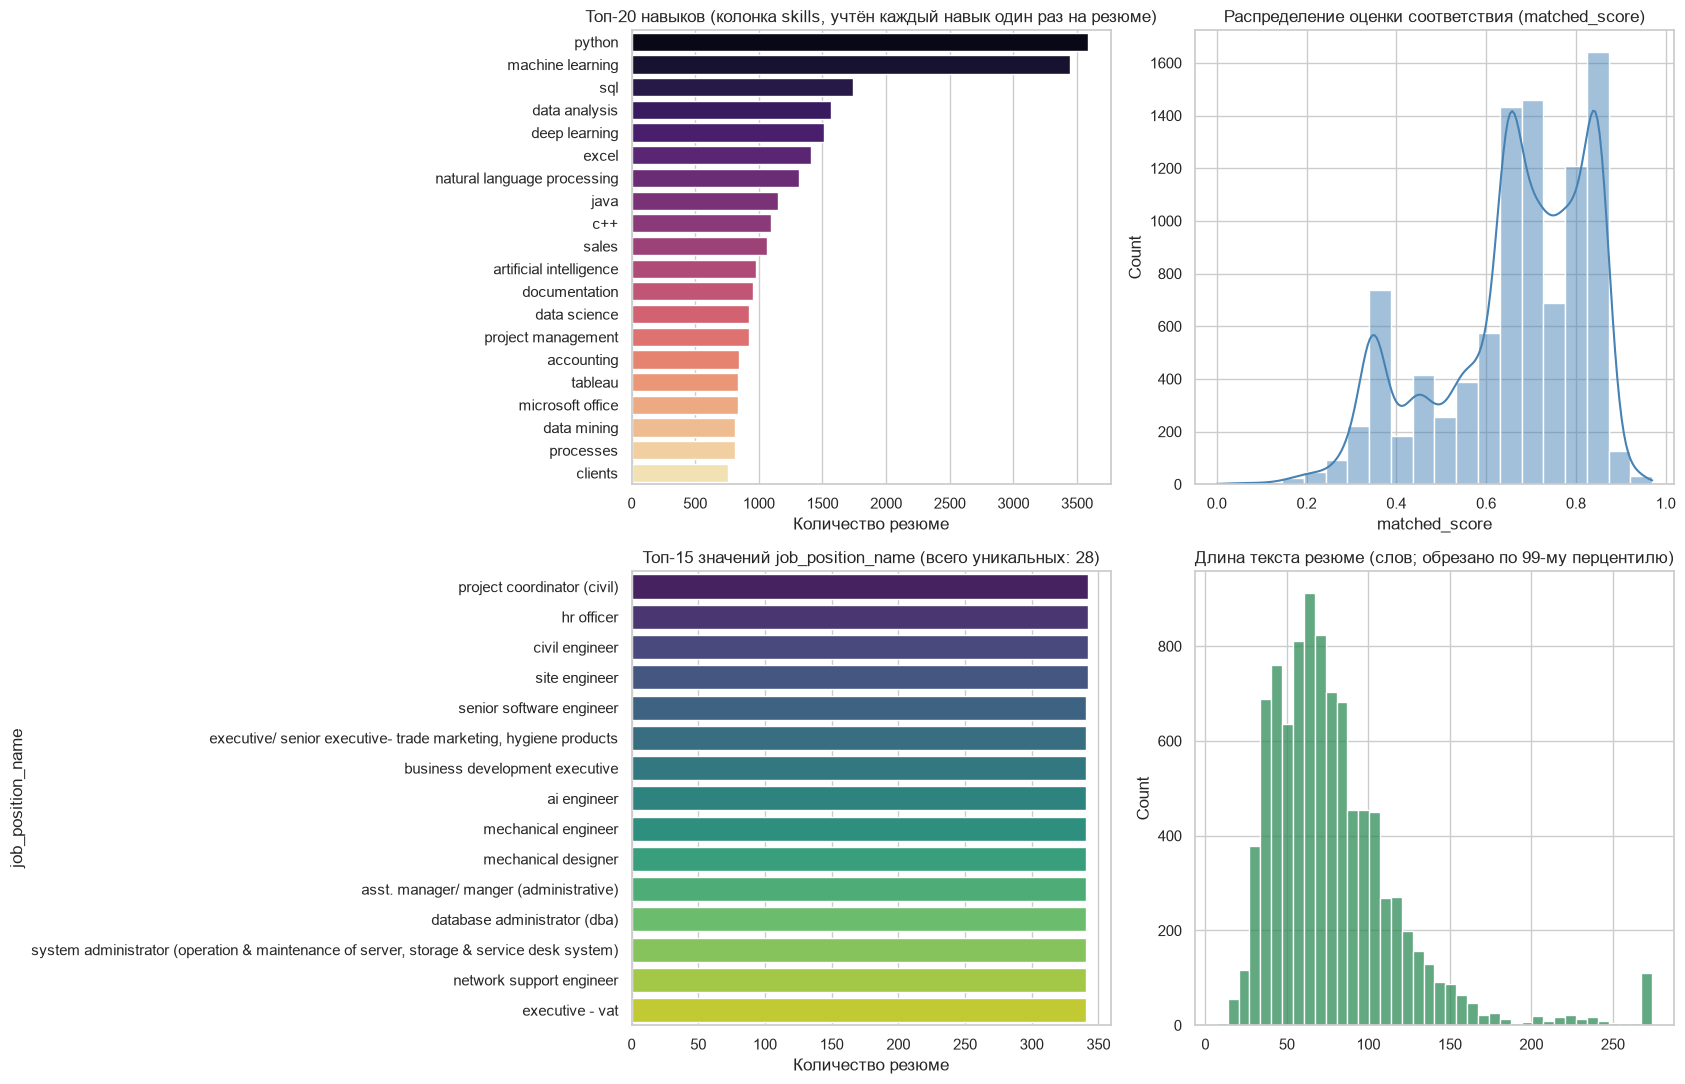

In [5]:
all_skill_sets = df_raw["skills"].dropna().map(parse_skills_gt)
top_skills = Counter(s for sk in all_skill_sets for s in sk).most_common(20)
labels_raw = df_raw[LABEL_COL].map(derive_label)
top_titles = labels_raw[labels_raw != ""].value_counts().head(15)
n_words_raw = (df_raw["career_objective"].map(to_plain_text) + " " + df_raw["skills"].map(to_plain_text)
               + " " + df_raw["responsibilities"].map(to_plain_text)).str.split().str.len()

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
sns.barplot(x=[x[1] for x in top_skills], y=[x[0] for x in top_skills], hue=[x[0] for x in top_skills],
            palette='magma', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Топ-20 навыков (колонка skills, учтён каждый навык один раз на резюме)')
axes[0, 0].set_xlabel('Количество резюме')

scores = pd.to_numeric(df_raw['matched_score'], errors='coerce').dropna()
sns.histplot(scores, bins=20, kde=True, color='steelblue', ax=axes[0, 1])
axes[0, 1].set_title('Распределение оценки соответствия (matched_score)')
print(f"Статистика matched_score:\n{scores.describe().round(2)}")

sns.barplot(x=top_titles.values, y=top_titles.index, hue=top_titles.index, palette='viridis', legend=False, ax=axes[1, 0])
axes[1, 0].set_title(f'Топ-15 значений {LABEL_COL} (всего уникальных: {labels_raw.nunique()})')
axes[1, 0].set_xlabel('Количество резюме')

sns.histplot(n_words_raw.dropna().clip(upper=n_words_raw.quantile(0.99)), bins=40, color='seagreen', ax=axes[1, 1])
axes[1, 1].set_title('Длина текста резюме (слов; обрезано по 99-му перцентилю)')
plt.tight_layout(); plt.show()

## 4. Подготовка текстов и разбиение на `vocab` / `train` / `test`
* `resume_text` = цель + навыки + обязанности (как и раньше, но списки в виде строк `"['a', 'b']"` превращаются в обычный текст, чтобы скобки и кавычки не попадали в TF-IDF);
* `job_text` = название + требуемые навыки + обязанности вакансии;
* точные дубликаты резюме удаляются **до** разбиения — иначе копии одного и того же текста попали бы и в обучение, и в тест;
* разбиение стратифицировано по метке (редкие классы объединяются только для стратификации).

In [6]:
from sklearn.model_selection import train_test_split

df = df_raw.copy()
df["resume_text"] = (df["career_objective"].map(to_plain_text) + " " + df["skills"].map(to_plain_text)
                     + " " + df["responsibilities"].map(to_plain_text)).map(clean_text)
df["job_text"] = (df["job_position_name"].map(to_plain_text) + " " + df["skills_required"].map(to_plain_text)
                  + " " + df["responsibilities.1"].map(to_plain_text)).map(clean_text)
df["label"] = df[LABEL_COL].map(derive_label)
df["matched_score"] = pd.to_numeric(df["matched_score"], errors="coerce")
df["n_words"] = df["resume_text"].str.split().str.len()

n0 = len(df)
df = df[df["n_words"] >= 3]
n1 = len(df)
df = df.drop_duplicates(subset="resume_text").reset_index(drop=True)
print(f"Строк: {n0} → без пустых: {n1} → без дубликатов резюме: {len(df)}")

def split3(strat, fr, seed):
    assert abs(sum(fr.values()) - 1) < 1e-9
    idx = np.arange(len(strat))
    try:
        i_vocab, i_rest = train_test_split(idx, train_size=fr["vocab"], stratify=strat, random_state=seed)
        i_train, i_test = train_test_split(i_rest, train_size=fr["train"] / (fr["train"] + fr["test"]),
                                           stratify=strat[i_rest], random_state=seed)
    except ValueError as exc:
        print("Стратификация невозможна, используем обычное случайное разбиение:", exc)
        i_vocab, i_rest = train_test_split(idx, train_size=fr["vocab"], random_state=seed)
        i_train, i_test = train_test_split(i_rest, train_size=fr["train"] / (fr["train"] + fr["test"]), random_state=seed)
    return i_vocab, i_train, i_test

_cnt = Counter(df["label"])
_strat = np.array([l if (_cnt[l] >= 10 and l != "") else "__rare__" for l in df["label"]])
if 0 < (_strat == "__rare__").sum() < 3:                    # слишком маленькая «редкая» корзина ломает стратификацию
    _strat[_strat == "__rare__"] = Counter(_strat).most_common(1)[0][0]
i_vocab, i_train, i_test = split3(_strat, SPLIT_FRACTIONS, SEED)

df["split"] = ""
df.loc[i_vocab, "split"] = "vocab"
df.loc[i_train, "split"] = "train"
df.loc[i_test,  "split"] = "test"
assert (df["split"] != "").all() and len(set(i_vocab) & set(i_train)) == len(set(i_vocab) & set(i_test)) == len(set(i_train) & set(i_test)) == 0
assert df["resume_text"].is_unique, "дубликаты текстов между частями — утечка"

# классы для задач «резюме → вакансия»
_lab_counts = df.loc[df["label"] != "", "label"].value_counts()
CLASSES = [c for c, n in _lab_counts.items() if n >= MIN_PER_CLASS][:MAX_CLASSES]
if len(CLASSES) < 5:
    CLASSES = list(_lab_counts.index[:TOP_K_FALLBACK])
    print(f"⚠ Классов с >= {MIN_PER_CLASS} резюме меньше 5 — берём {len(CLASSES)} самых частых (метки редкие/разреженные).")
df["in_exp"] = df["label"].isin(CLASSES)

summary = df.groupby("split").agg(резюме=("resume_text", "size"), в_экспериментах=("in_exp", "sum"),
                                  классов=("label", lambda s: s[s.isin(CLASSES)].nunique()))
display(summary.loc[["vocab", "train", "test"]])
print(f"Классов в экспериментах: {len(CLASSES)}; покрыто {df['in_exp'].mean():.1%} резюме; "
      f"доля мажоритарного класса: {df.loc[df.in_exp, 'label'].value_counts(normalize=True).iloc[0]:.1%}")

Строк: 9544 → без пустых: 9544 → без дубликатов резюме: 9516


,резюме,в_экспериментах,классов
split,,,
vocab,3806,3806,28
train,3806,3806,28
test,1904,1904,28


Классов в экспериментах: 28; покрыто 100.0% резюме; доля мажоритарного класса: 3.6%


## 5. Извлечение навыков (NER) — словарь строится только из части `vocab`
**Что было не так.** Словарь `EntityRuler` строился из колонок `skills` и `related_skils_in_job` **всех** резюме, а затем качество считалось на первых 200 строках **того же** датасета, подавая на вход ту же колонку `skills`. Это измеряет, насколько словарь знает собственный источник (утечка), а не способность находить навыки в новых резюме. Кроме того, `related_skils_in_job` входило в эталон, но не во вход — это искусственно занижало recall.

**Как теперь.**
* Словарь = навыки из части `vocab` + кураторский список `EXTRA_SKILLS` (он же `SKILLS_VOCAB` из `nlp_pipeline.py`).
* Оценка — на части `test` (резюме, которых нет ни в словаре, ни в обучении TF-IDF). Вход: тексты полей `skills` и `related_skils_in_job`; эталон: объединение их разобранных значений — то есть эталон полностью выводим из входа.
* Для наглядности сравниваются варианты: старый протокол, «утёкший» словарь, честный словарь, честный словарь без кураторского списка, только кураторский список.
* Паттерны строятся токенизатором spaCy (`nlp.make_doc`), а не `str.split()`.
* Для нормализованных навыков добавляются паттерны-алиасы (`react` → `react.js`, `machine learning` → `ml`): раньше `react.js` нормализовался в `react` ещё до построения словаря, и написание «React.js» в тексте не находилось.

In [7]:
EXTRA_SKILLS = [
    # Languages
    "python", "javascript", "typescript", "java", "c++", "c#", "golang", "rust",
    "kotlin", "swift", "scala", "r", "php", "ruby", "bash", "sql", "html", "css",
    "sass", "core java",
    # ML / AI
    "machine learning", "deep learning", "natural language processing",
    "computer vision", "data science", "data analysis", "data engineering",
    "scikit-learn", "tensorflow", "pytorch", "keras", "hugging face",
    "transformers", "bert", "gpt", "langchain", "openai", "llm",
    "reinforcement learning", "feature engineering", "model deployment",
    "mlflow", "xgboost", "lightgbm", "catboost", "random forest",
    "neural network", "convolutional neural network", "recurrent neural network",
    "risk prediction", "big data",
    # Data
    "data visualization", "data analytics", "business analytics", "business analysis",
    "data warehousing", "business intelligence", "tableau", "power bi",
    "apache spark", "spark", "pyspark", "hadoop", "hive", "kafka", "airflow",
    "dbt", "etl", "pandas", "numpy", "matplotlib", "seaborn",
    "amazon redshift", "google bigquery", "azure synapse", "snowflake",
    # Cloud & DevOps
    "aws", "azure", "gcp", "docker", "kubernetes", "terraform", "ansible",
    "ci/cd", "github actions", "jenkins", "linux", "nginx", "redis",
    "cloud computing", "microservices", "serverless",
    # Databases
    "postgresql", "mongodb", "mysql", "sqlite", "elasticsearch", "cassandra",
    "dynamodb", "firebase", "nosql",
    # Backend
    "fastapi", "flask", "django", "spring boot", "node.js", "express.js",
    "rest api", "graphql", "grpc", "websocket", "celery",
    # Frontend
    "react", "react.js", "vue.js", "angular", "next.js", "nuxt.js",
    "tailwind", "webpack", "vite", "redux", "typescript",
    # Tools
    "git", "github", "gitlab", "jira", "confluence", "figma",
    "agile", "scrum", "kanban",
    # Other
    "application support", "network security", "system administration",
    "unity", "unreal engine", "opencv", "selenium", "pytest",
]
CURATED = {normalize_skill(s) for s in EXTRA_SKILLS}

ALIASES = defaultdict(set)                                    # нормализованный навык -> написания, которые к нему приводятся
for _alias, _canon in TECH_NORMALIZATIONS.items():
    ALIASES[_canon].add(_alias)

def skills_from_rows(rows) -> set:
    out = set()
    for col in ("skills", "related_skils_in_job"):
        for raw in rows[col].dropna():
            out |= parse_skills_gt(raw)
    return out

def build_ner(skills, base="blank"):
    """EntityRuler со словарём skills. base='blank' — быстрый вариант для оценки (токенизатор идентичен en_core_web_md),
    base='md' — продуктовая модель (как раньше: en_core_web_md без NER + EntityRuler)."""
    nlp_ = spacy.blank("en") if base == "blank" else spacy.load(SPACY_MODEL, disable=["ner"])
    ruler = nlp_.add_pipe("entity_ruler", config={"overwrite_ents": True})
    # Навыки хранятся в нормализованном виде ('react'), а в тексте встречаются написания-алиасы ('react.js', 'NLP', 'K8s').
    # Паттерны строим и для нормализованной формы, и для её алиасов (из TECH_NORMALIZATIONS); на выходе всё снова нормализуется.
    forms = set()
    for sk in skills:
        forms.add(sk.strip())
        forms.update(ALIASES.get(sk.strip(), ()))
    seen, patterns = set(), []
    for sk in sorted(forms):
        if len(sk) < 2:
            continue
        toks = tuple(t.lower_ for t in nlp_.make_doc(sk))
        if toks and toks not in seen:
            seen.add(toks)
            patterns.append({"label": "SKILL", "pattern": [{"LOWER": t} for t in toks]})
    ruler.add_patterns(patterns)
    return nlp_, len(patterns)

def predict_skills(nlp_, texts, batch_size=128):
    return [{normalize_skill(e.text) for e in doc.ents if e.label_ == "SKILL"}
            for doc in nlp_.pipe([clean_text(t) for t in texts], batch_size=batch_size)]

def eval_ner(preds, golds):
    TP = FP = FN = 0
    P, R, F = [], [], []
    fn_c, fp_c = Counter(), Counter()
    for p, g in zip(preds, golds):
        if not p and not g:
            continue
        tp, fp, fn = p & g, p - g, g - p
        TP += len(tp); FP += len(fp); FN += len(fn)
        fn_c.update(fn); fp_c.update(fp)
        pr = len(tp) / len(p) if p else 0.0
        rc = len(tp) / len(g) if g else 0.0
        P.append(pr); R.append(rc); F.append(2 * pr * rc / (pr + rc) if pr + rc else 0.0)
    p_ = TP / (TP + FP) if TP + FP else 0.0
    r_ = TP / (TP + FN) if TP + FN else 0.0
    return dict(n_docs=len(F), TP=TP, FP=FP, FN=FN,
                P_micro=p_, R_micro=r_, F1_micro=2 * p_ * r_ / (p_ + r_) if p_ + r_ else 0.0,
                P_macro=float(np.mean(P)), R_macro=float(np.mean(R)), F1_macro=float(np.mean(F)),
                fn_counter=fn_c, fp_counter=fp_c)

def ner_gold(rows):
    return [parse_skills_gt(a) | parse_skills_gt(b) for a, b in zip(rows["skills"], rows["related_skils_in_job"])]

def ner_input(rows, mode="fixed"):
    if mode == "skills_only":
        return [to_plain_text(a) for a in rows["skills"]]
    return [to_plain_text(a) + ", " + to_plain_text(b) for a, b in zip(rows["skills"], rows["related_skils_in_job"])]

vocab_rows = df[df["split"] == "vocab"]
test_rows  = df[df["split"] == "test"]
VOCAB_SKILLS = skills_from_rows(vocab_rows)           # только из части vocab
ALL_SKILLS   = skills_from_rows(df)                   # для демонстрации утечки
print(f"Навыков в части vocab: {len(VOCAB_SKILLS)} | во всём датасете: {len(ALL_SKILLS)} | кураторский список: {len(CURATED)}")
print(f"Навыков из теста, которых нет в vocab-части: {len(skills_from_rows(test_rows) - VOCAB_SKILLS)} из {len(skills_from_rows(test_rows))}")

Навыков в части vocab: 3911 | во всём датасете: 3911 | кураторский список: 138
Навыков из теста, которых нет в vocab-части: 0 из 3907


In [8]:
gold_test = ner_gold(test_rows)
variants = {}

# (0) старый протокол: словарь из ВСЕХ строк, первые 200 строк, вход = только skills, эталон = skills ∪ related
old_rows = df.dropna(subset=["skills"]).head(200)
nlp_old, n_old = build_ner(ALL_SKILLS | CURATED)
variants["0. Старый протокол (словарь из всех строк, 200 строк, вход=skills)"] = (
    eval_ner(predict_skills(nlp_old, ner_input(old_rows, "skills_only")), ner_gold(old_rows)), n_old)

# (1) утечка: словарь из всех строк (включая test), новый протокол, тест
variants["1. Утечка: словарь из ВСЕХ строк, оценка на test"] = (
    eval_ner(predict_skills(nlp_old, ner_input(test_rows)), gold_test), n_old)

# (2) ЧЕСТНО: vocab-часть + кураторский список   ← используется дальше и сохраняется
nlp_eval, n_eval = build_ner(VOCAB_SKILLS | CURATED)
preds_test = predict_skills(nlp_eval, ner_input(test_rows))
res_main = eval_ner(preds_test, gold_test)
variants["2. ЧЕСТНО: vocab-часть + кураторский список (используется в продукте)"] = (res_main, n_eval)

# (3) честно, без кураторского списка
nlp_nocur, n_nocur = build_ner(VOCAB_SKILLS)
variants["3. Честно, только vocab-часть (без кураторского списка)"] = (eval_ner(predict_skills(nlp_nocur, ner_input(test_rows)), gold_test), n_nocur)

# (4) только кураторский список (словарь «из головы»)
nlp_cur, n_cur = build_ner(CURATED)
variants["4. Только кураторский список (без данных)"] = (eval_ner(predict_skills(nlp_cur, ner_input(test_rows)), gold_test), n_cur)

ner_table = pd.DataFrame(
    [{"вариант": k, "паттернов": n, "docs": r["n_docs"], "P (micro)": r["P_micro"], "R (micro)": r["R_micro"],
      "F1 (micro)": r["F1_micro"], "P (macro)": r["P_macro"], "R (macro)": r["R_macro"], "F1 (macro)": r["F1_macro"]}
     for k, (r, n) in variants.items()]).set_index("вариант")
display(ner_table.round(3))

leak_gap = variants["1. Утечка: словарь из ВСЕХ строк, оценка на test"][0]["F1_micro"] - res_main["F1_micro"]
print(f"\nЗавышение F1(micro) из-за утечки словаря: {leak_gap:+.3f} (утечка {variants['1. Утечка: словарь из ВСЕХ строк, оценка на test'][0]['F1_micro']:.3f} → честно {res_main['F1_micro']:.3f})")

,паттернов,docs,P (micro),R (micro),F1 (micro),P (macro),R (macro),F1 (macro)
вариант,,,,,,,,
"0. Старый протокол (словарь из всех строк, 200 строк, вход=skills)",3970,199,0.999,0.781,0.877,0.999,0.805,0.877
"1. Утечка: словарь из ВСЕХ строк, оценка на test",3970,1891,1.000,0.999,1.000,1.000,1.000,1.000
2. ЧЕСТНО: vocab-часть + кураторский список (используется в продукте),3970,1891,1.000,0.999,1.000,1.000,1.000,1.000
"3. Честно, только vocab-часть (без кураторского списка)",3922,1891,1.000,0.999,1.000,1.000,1.000,1.000
4. Только кураторский список (без данных),146,1891,0.930,0.136,0.237,0.581,0.252,0.326



Завышение F1(micro) из-за утечки словаря: +0.000 (утечка 1.000 → честно 1.000)


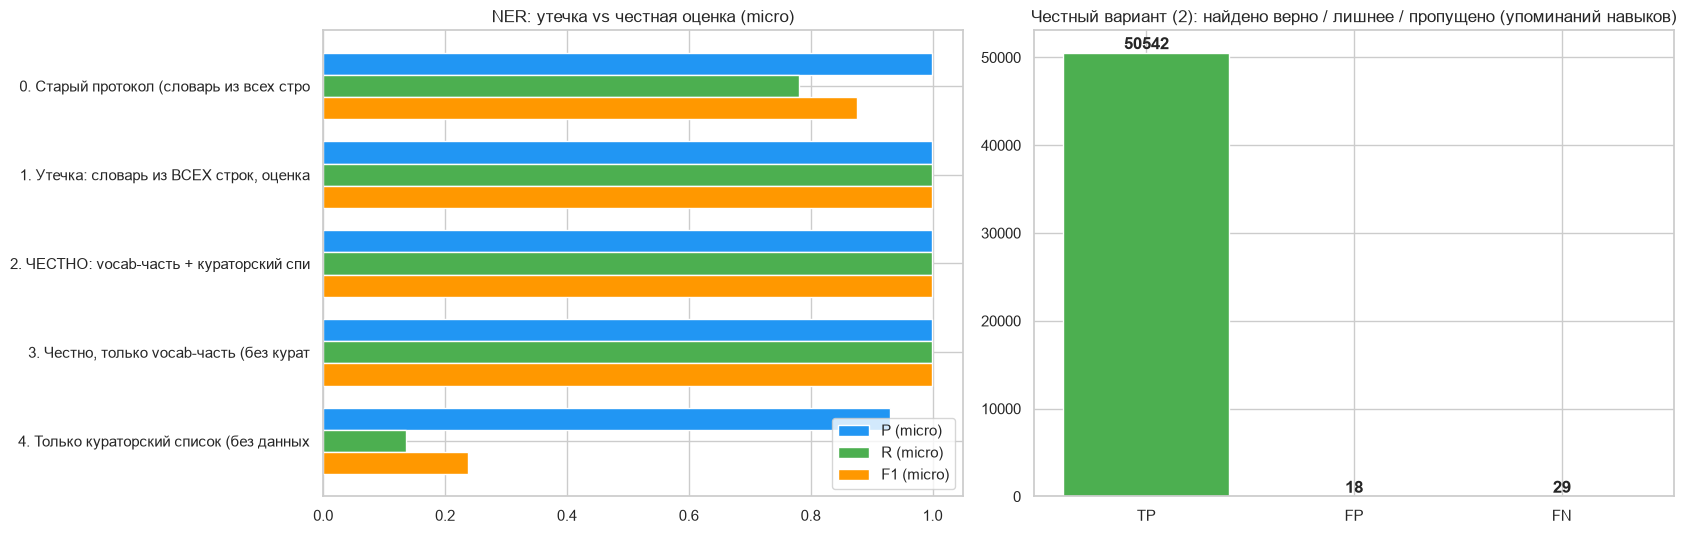

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
plot_df = ner_table[["P (micro)", "R (micro)", "F1 (micro)"]].copy()
plot_df.index = [i.split(".")[0] + "." + i.split(".")[1][:38] for i in plot_df.index]
plot_df.plot(kind="barh", ax=axes[0], color=['#2196F3', '#4CAF50', '#FF9800'], width=0.75)
axes[0].set_xlim(0, 1.05); axes[0].invert_yaxis(); axes[0].set_title("NER: утечка vs честная оценка (micro)")
axes[0].legend(loc="lower right")
axes[1].bar(["TP", "FP", "FN"], [res_main["TP"], res_main["FP"], res_main["FN"]], color=["#4CAF50", "#F44336", "#9E9E9E"])
for i, v in enumerate([res_main["TP"], res_main["FP"], res_main["FN"]]):
    axes[1].text(i, v, str(v), ha="center", va="bottom", fontweight="bold")
axes[1].set_title("Честный вариант (2): найдено верно / лишнее / пропущено (упоминаний навыков)")
plt.tight_layout(); plt.show()

### Разбор ошибок NER (честный вариант)
Здесь «матрица ошибок» для NER — это TP/FP/FN (у извлечения навыков нет понятия TN). Ниже — какие навыки пропускаются, где лишние срабатывания, и как recall зависит от того, сколько раз навык встречался в `vocab`-части.

Пропущено упоминаний (FN): 29; из них навыка нет в словаре (OOV): 0 (0%); навык есть в словаре, но не найден: 29
  примеры «есть в словаре, но не найден»: ['real estate p.m.a.s.', '2k', 'project and visio', 'microsoft excel', 'node.js']


,упоминаний в test,найдено,recall
встречался в vocab-части (раз),,,
0 (не встречался),0,0,NaN
1,0,0,NaN
2–4,228,223,0.978
5+,50343,50319,1.000


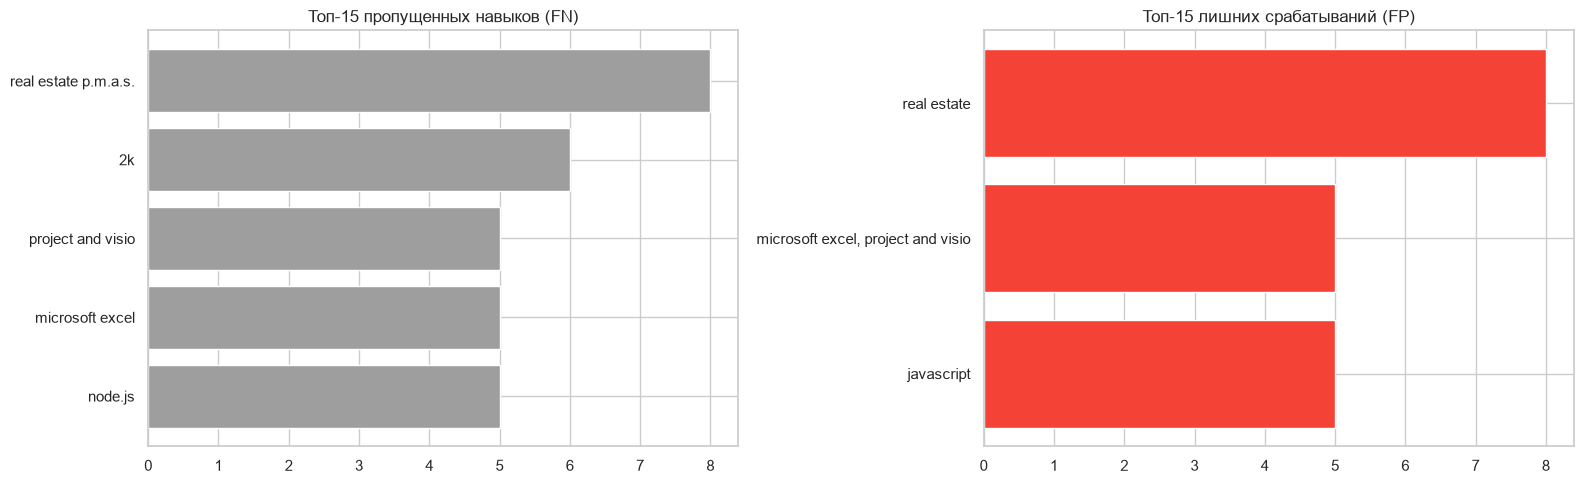

Примеры документов с ошибками:
  вход : 3d, accounting, Accountant, Accounts receivables, Adobe Illustrator, Adobe Photoshop, Pagemaker, Audio Editing, auditing, banking, book, Bud…
  FN   : ['2k']   FP: []
  вход : Excellent communication techniques, Engineering standards expert, Complex problem solver, Advanced critical thinking, Microsoft Excel, Proje…
  FN   : ['microsoft excel', 'project and visio']   FP: ['microsoft excel, project and visio']
  вход : 3d, accounting, Accountant, Accounts receivables, Adobe Illustrator, Adobe Photoshop, Pagemaker, Audio Editing, auditing, banking, book, Bud…
  FN   : ['2k']   FP: []
  вход : Analytical reasoning, Budget forecasting expertise, Account reconciliation expert, Financial planner, Effective time management, Advanced co…
  FN   : ['real estate p.m.a.s.']   FP: ['real estate']


In [10]:
vocab_freq = Counter(s for raw in vocab_rows["skills"].dropna() for s in parse_skills_gt(raw))
for raw in vocab_rows["related_skils_in_job"].dropna():
    for s in parse_skills_gt(raw):
        vocab_freq[s] += 1
pattern_skills = VOCAB_SKILLS | CURATED

fn_c, fp_c = res_main["fn_counter"], res_main["fp_counter"]
fn_oov   = sum(c for s, c in fn_c.items() if s not in pattern_skills)         # навыка нет в словаре вообще
fn_in_v  = sum(c for s, c in fn_c.items() if s in pattern_skills)             # навык в словаре, но не найден (проблема токенизации/совпадения)
print(f"Пропущено упоминаний (FN): {res_main['FN']}; из них навыка нет в словаре (OOV): {fn_oov} ({fn_oov / max(1, res_main['FN']):.0%}); "
      f"навык есть в словаре, но не найден: {fn_in_v}")
if fn_in_v:
    print("  примеры «есть в словаре, но не найден»:", [s for s, _ in fn_c.most_common() if s in pattern_skills][:10])

# recall по частоте навыка в vocab-части
def bucket(skill):
    f = vocab_freq.get(skill, 0)
    return "0 (не встречался)" if f == 0 else "1" if f == 1 else "2–4" if f < 5 else "5+"
tot, hit = Counter(), Counter()
for p, g in zip(preds_test, gold_test):
    for s in g:
        tot[bucket(s)] += 1
        hit[bucket(s)] += int(s in p)
order = ["0 (не встречался)", "1", "2–4", "5+"]
rec_b = pd.DataFrame({"упоминаний в test": [tot[b] for b in order], "найдено": [hit[b] for b in order]}, index=order)
rec_b["recall"] = rec_b["найдено"] / rec_b["упоминаний в test"].replace(0, np.nan)
display(rec_b.round(3).rename_axis("встречался в vocab-части (раз)"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, cnt, title, color in [(axes[0], fn_c, "Топ-15 пропущенных навыков (FN)", "#9E9E9E"),
                              (axes[1], fp_c, "Топ-15 лишних срабатываний (FP)", "#F44336")]:
    items = cnt.most_common(15)
    if items:
        ax.barh([i[0] for i in items][::-1], [i[1] for i in items][::-1], color=color)
    ax.set_title(title)
plt.tight_layout(); plt.show()

print("Примеры документов с ошибками:")
shown = 0
for txt, p, g in zip(ner_input(test_rows), preds_test, gold_test):
    if (g - p) or (p - g):
        print(f"  вход : {txt[:140]}…")
        print(f"  FN   : {sorted(g - p)[:6]}   FP: {sorted(p - g)[:6]}")
        shown += 1
        if shown == 4:
            break
if shown == 0:
    print("  (ошибок нет)")

## 6. Matching: TF-IDF обучается только на части `train`
Skill Overlap — доля требуемых навыков вакансии, найденных у кандидата. TF-IDF + cosine — сходство текстов. Векторизатор раньше обучался на **всех** 9 544 резюме; теперь — только на части `train` (она не пересекается ни с `vocab`, ни с `test`).

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize as sk_normalize

TFIDF_PARAMS = dict(ngram_range=(1, 2), stop_words='english', max_features=10000, sublinear_tf=True)

def skill_overlap_score(resume_skills, job_skills) -> dict:
    resume_set = {normalize_skill(s) for s in resume_skills}
    job_set = {normalize_skill(s) for s in job_skills}
    if not job_set:
        return {"score": 0.0, "matched": [], "missing": [], "extra": []}
    matched, missing, extra = resume_set & job_set, job_set - resume_set, resume_set - job_set
    return {"score": round(len(matched) / len(job_set), 3), "matched": sorted(matched),
            "missing": sorted(missing), "extra": sorted(extra)}

class ResumeJobMatcher:
    def __init__(self, **params):
        self.vectorizer = TfidfVectorizer(**(params or TFIDF_PARAMS))
    def fit(self, corpus):
        self.vectorizer.fit(corpus)
        return self
    def match(self, resume_text: str, job_description: str) -> float:
        vectors = self.vectorizer.transform([resume_text, job_description])
        return round(float(cosine_similarity(vectors[0], vectors[1])[0][0]), 4)

train_texts_all = df.loc[df["split"] == "train", "resume_text"].tolist()
matcher = ResumeJobMatcher().fit(train_texts_all)
print(f"Матчер обучен на {len(train_texts_all)} резюме части train ({len(matcher.vectorizer.vocabulary_)} терминов)")

Матчер обучен на 3806 резюме части train (10000 терминов)


## 7. Вспомогательные функции оценки (классификация, поиск, время/память)
* классификация: Accuracy и Macro-F1 (усреднение по классам, присутствующим в тесте) + bootstrap 95% CI;
* поиск: Precision@k и MRR, релевантным считается документ-вакансия с тем же названием должности;
* ресурсы: время (`perf_counter`), пик памяти Python/NumPy (`tracemalloc`, отдельный проход, чтобы трассировка не искажала время) и прирост RSS процесса (видит и C-память: spaCy, torch).

In [12]:
from sklearn.metrics import accuracy_score, f1_score

CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
K = len(CLASSES)

def to_ids(y):
    return np.array([CLASS_ID[v] for v in y])

def _acc_f1(yt, yp):
    cm = np.bincount(yt * K + yp, minlength=K * K).reshape(K, K)
    tp, sup, pr = np.diag(cm).astype(float), cm.sum(1), cm.sum(0)
    p = np.divide(tp, pr, out=np.zeros(K), where=pr > 0)
    r = np.divide(tp, sup, out=np.zeros(K), where=sup > 0)
    f = np.divide(2 * p * r, p + r, out=np.zeros(K), where=(p + r) > 0)
    return tp.sum() / len(yt), f[sup > 0].mean()

def clf_scores(y_true, y_pred):
    acc, f1 = _acc_f1(to_ids(y_true), to_ids(y_pred))
    return dict(accuracy=float(acc), macro_f1=float(f1))

def bootstrap_ci(y_true, y_pred, n=None, seed=SEED):
    n = n or BOOTSTRAP
    r = np.random.default_rng(seed)
    yt, yp = to_ids(y_true), to_ids(y_pred)
    res = np.array([_acc_f1(yt[i], yp[i]) for i in (r.integers(0, len(yt), len(yt)) for _ in range(n))])
    return {"acc_ci": tuple(np.percentile(res[:, 0], [2.5, 97.5])), "f1_ci": tuple(np.percentile(res[:, 1], [2.5, 97.5]))}

# контроль: быстрая реализация совпадает с sklearn
_yt = np.array(CLASSES * 3); _yp = np.array(CLASSES[1:] + CLASSES[:1] + CLASSES * 2)
assert abs(clf_scores(_yt, _yp)["macro_f1"] - f1_score(_yt, _yp, labels=sorted(set(_yt)), average="macro")) < 1e-9

def retrieval_metrics(S, REL, ks=(1, 5, 10)):
    order = np.argsort(-S, axis=1, kind="stable")
    rel_sorted = np.take_along_axis(REL, order, axis=1)
    out = {f"P@{k}": float(rel_sorted[:, :k].mean()) for k in ks}
    has = rel_sorted.any(axis=1)
    out["MRR"] = float(np.mean(np.where(has, 1.0 / (rel_sorted.argmax(axis=1) + 1), 0.0)))
    return out

_proc = psutil.Process()
def profile_run(fn, trace=True):
    """Возвращает (результат, секунды, пик tracemalloc MB | None, прирост RSS MB). Память меряется вторым проходом."""
    gc.collect()
    rss0 = _proc.memory_info().rss
    t0 = time.perf_counter(); out = fn(); dt = time.perf_counter() - t0
    drss = (_proc.memory_info().rss - rss0) / 2**20
    peak = None
    if trace:
        gc.collect(); tracemalloc.start(); fn(); peak = tracemalloc.get_traced_memory()[1] / 2**20; tracemalloc.stop()
    return out, dt, peak, drss

def sparse_mb(X):
    return (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 2**20 if hasattr(X, "indptr") else X.nbytes / 2**20

## 8. Стемминг vs лемматизация
Сравниваем **Porter** и **Snowball** (NLTK) со **spaCy-лемматизатором** (`en_core_web_md`, правила + POS-теги) на резюме частей `train` и `test` (часть `vocab` не используется). Токены: только буквенные, не стоп-слова, длиннее 1 символа.
Смотрим: (1) примеры, (2) размер словаря и «нечитаемые» формы, (3) склейки и недосклейки, (4) что происходит с названиями технологий, (5) скорость, (6) влияние на качество классификации.

In [13]:
from nltk.stem import PorterStemmer, SnowballStemmer
porter, snowball = PorterStemmer(), SnowballStemmer("english")
nlp_lem = spacy.load(SPACY_MODEL, exclude=["ner", "parser"])      # tok2vec + tagger + attribute_ruler + lemmatizer

EXAMPLE_SENTENCES = [
    "Developed and deployed machine learning models, analyzing large databases and optimizing queries.",
    "Managed 5 engineers; the studies showed our pipelines were running better after the migrations.",
    "Experienced with Pandas, Kubernetes, Redis and Tableau; built dashboards for universities and universal services.",
    "Led analyses of data and operations, relying on statistics, libraries and APIs.",
]
rows = []
for doc in nlp_lem.pipe(EXAMPLE_SENTENCES):
    for t in doc:
        if t.is_alpha:
            w = t.lower_
            rows.append((w, t.pos_, porter.stem(w), snowball.stem(w), t.lemma_.lower()))
ex = pd.DataFrame(rows, columns=["слово", "POS", "Porter", "Snowball", "spaCy lemma"]).drop_duplicates("слово")
ex["стем ≠ лемма"] = (ex["Porter"] != ex["spaCy lemma"]) | (ex["Snowball"] != ex["spaCy lemma"])
display(ex[ex["стем ≠ лемма"] | (ex["слово"] != ex["spaCy lemma"])].reset_index(drop=True).head(45))

,слово,POS,Porter,Snowball,spaCy lemma,стем ≠ лемма
0,developed,VERB,develop,develop,develop,False
1,deployed,VERB,deploy,deploy,deploy,False
2,machine,NOUN,machin,machin,machine,True
3,learning,NOUN,learn,learn,learning,True
4,models,NOUN,model,model,model,False
5,analyzing,VERB,analyz,analyz,analyze,True
6,large,ADJ,larg,larg,large,True
7,databases,NOUN,databas,databas,database,True
8,optimizing,VERB,optim,optim,optimize,True
9,queries,NOUN,queri,queri,query,True


In [14]:
norm_rows = df[df["split"].isin(["train", "test"])]
if NORM_MAX_DOCS:
    norm_rows = norm_rows.head(NORM_MAX_DOCS)
n_all_tokens = 0
tok_lists, lem_lists = [], []
t0 = time.perf_counter()
for doc in nlp_lem.pipe(norm_rows["resume_text"].tolist(), batch_size=32):
    n_all_tokens += len(doc)
    toks = [t for t in doc if t.is_alpha and not t.is_stop and len(t) > 1]
    tok_lists.append([t.lower_ for t in toks])
    lem_lists.append([t.lemma_.lower() for t in toks])
t_spacy = time.perf_counter() - t0
flat = [w for l in tok_lists for w in l]
print(f"Документов: {len(norm_rows)}, токенов всего: {n_all_tokens}, после фильтра: {len(flat)}; spaCy (токенизация+теггер+лемматизатор): {t_spacy:.1f} с")

def stem_lists(stemmer, lists):
    cache, out = {}, []
    for l in lists:
        o = []
        for w in l:
            s = cache.get(w)
            if s is None:
                s = cache[w] = stemmer.stem(w)
            o.append(s)
        out.append(o)
    return out

NORM = {"raw": tok_lists, "porter": stem_lists(porter, tok_lists), "snowball": stem_lists(snowball, tok_lists), "lemma": lem_lists}

# скорость: стеммеры на выборке токенов (без кэша) vs полный spaCy-проход
sample = flat[:150_000]
def tok_per_s(stemmer):
    t = time.perf_counter(); [stemmer.stem(w) for w in sample]; return len(sample) / (time.perf_counter() - t)
nlp_tok = spacy.blank("en")
_sample_docs = norm_rows["resume_text"].tolist()[:500]
_n_tok = sum(len(d) for d in nlp_tok.pipe(_sample_docs))                      # заодно «прогрев»
_t = time.perf_counter(); _ = [d for d in nlp_tok.pipe(_sample_docs)]; tok_only = _n_tok / (time.perf_counter() - _t)
speed = pd.DataFrame({"токенов/с": {"только токенизация spaCy": tok_only, "Porter (на готовых токенах)": tok_per_s(porter),
                                     "Snowball (на готовых токенах)": tok_per_s(snowball), "spaCy: токенизация+теггер+лемматизатор": n_all_tokens / t_spacy}}).round(0)
display(speed)

Документов: 5710, токенов всего: 614174, после фильтра: 395299; spaCy (токенизация+теггер+лемматизатор): 41.8 с


,токенов/с
только токенизация spaCy,1356581.0
Porter (на готовых токенах),51908.0
Snowball (на готовых токенах),81779.0
spaCy: токенизация+теггер+лемматизатор,14693.0


In [15]:
surface = Counter(flat)
surface_types = set(surface)
stats = []
for name, lists in NORM.items():
    types = {w for l in lists for w in l}
    cv2 = CountVectorizer(ngram_range=(2, 2), token_pattern=r"(?u)\b\w+\b", lowercase=False)
    cv2.fit([" ".join(l) for l in lists])
    stats.append({"нормализация": name, "типов (униграммы)": len(types),
                  "сжатие словаря vs raw": 1 - len(types) / len(surface_types),
                  "типов (биграммы)": len(cv2.vocabulary_),
                  "% типов, которых нет как слов в корпусе": len(types - surface_types) / len(types)})
    del cv2
stats = pd.DataFrame(stats).set_index("нормализация")
display(stats.round(3))

# склейки (несколько лемм → один стем) и недосклейки (одна лемма → несколько стемов)
lemma_of = defaultdict(Counter)
for tl, ll in zip(tok_lists, lem_lists):
    for w, l in zip(tl, ll):
        lemma_of[w][l] += 1
lemma_of = {w: c.most_common(1)[0][0] for w, c in lemma_of.items()}
stem_of = {w: porter.stem(w) for w in surface}
stem_freq, stem_lemmas, lemma_stems = Counter(), defaultdict(set), defaultdict(set)
for w, c in surface.items():
    stem_freq[stem_of[w]] += c
    stem_lemmas[stem_of[w]].add(lemma_of[w])
    lemma_stems[lemma_of[w]].add(stem_of[w])
over  = [(s, sorted(l)[:6], stem_freq[s]) for s, l in stem_lemmas.items() if len(l) >= 2]
over.sort(key=lambda x: -x[2])
lemma_freq = Counter()
for w, c in surface.items():
    lemma_freq[lemma_of[w]] += c
under = [(l, sorted(s), lemma_freq[l]) for l, s in lemma_stems.items() if len(s) >= 2]
under.sort(key=lambda x: -x[2])
print(f"Porter склеивает >=2 разных лемм в один стем у {len(over)} стемов; лемма делится на >=2 стема у {len(under)} лемм.\n")
print("Склейки (частые): стем ← леммы   [часть полезна: manager/management → manag; часть — ошибка смысла]")
for s, l, f in over[:12]:
    print(f"  {s:12s} ← {l}")
print("\nНедосклейки (одна лемма — несколько стемов): лемма → стемы")
for l, s, f in under[:10]:
    print(f"  {l:12s} → {s}")

,типов (униграммы),сжатие словаря vs raw,типов (биграммы),"% типов, которых нет как слов в корпусе"
нормализация,,,,
raw,2972,0.000,14532,0.000
porter,2268,0.237,13760,0.461
snowball,2272,0.236,13763,0.438
lemma,2795,0.060,14549,0.071


Porter склеивает >=2 разных лемм в один стем у 319 стемов; лемма делится на >=2 стема у 15 лемм.

Склейки (частые): стем ← леммы   [часть полезна: manager/management → manag; часть — ошибка смысла]
  manag        ← ['manage', 'management', 'manager', 'managing']
  learn        ← ['learn', 'learning']
  develop      ← ['develop', 'developer', 'development']
  design       ← ['design', 'designer', 'designing']
  machin       ← ['machine', 'machining']
  softwar      ← ['software', 'softwares']
  system       ← ['system', 'systems']
  process      ← ['process', 'processing']
  account      ← ['account', 'accountable', 'accountant', 'accounting']
  collabor     ← ['collaborate', 'collaboration', 'collaborative', 'collaboratively']
  document     ← ['document', 'documentation', 'documenting', 'documents']
  team         ← ['team', 'teams']

Недосклейки (одна лемма — несколько стемов): лемма → стемы
  analysis     → ['analys', 'analysi']
  experience   → ['experi', 'experienc']
  deep       

In [16]:
# что происходит с названиями технологий (однословные навыки из vocab-части)
vocab_freq_all = Counter(s for raw in vocab_rows["skills"].dropna() for s in parse_skills_gt(raw))
single = [s for s, _ in vocab_freq_all.most_common() if re.fullmatch(r"[a-z]{3,}", s)][:300]
ch_porter  = {s: porter.stem(s) for s in single if porter.stem(s) != s}
ch_snow    = {s: snowball.stem(s) for s in single if snowball.stem(s) != s}
ch_lemma = {}
for s, d in zip(single, nlp_lem.pipe([f"Experience with {s} and other tools." for s in single])):
    cand = [t for t in d if t.lower_ == s]
    if cand and cand[0].lemma_.lower() != s:
        ch_lemma[s] = cand[0].lemma_.lower()
tech = pd.DataFrame({"Porter": [len(ch_porter) / len(single)], "Snowball": [len(ch_snow) / len(single)],
                     "spaCy lemma": [len(ch_lemma) / len(single)]}, index=[f"доля из топ-{len(single)} однословных навыков, которые меняются"]).T
display(tech.round(3))
print("Примеры искажения названий технологий:")
print("  Porter  :", dict(list(ch_porter.items())[:10]))
print("  Snowball:", dict(list(ch_snow.items())[:10]))
print("  lemma   :", dict(list(ch_lemma.items())[:10]))

,"доля из топ-300 однословных навыков, которые меняются"
Porter,0.613
Snowball,0.597
spaCy lemma,0.207


Примеры искажения названий технологий:
  Porter  : {'sales': 'sale', 'documentation': 'document', 'accounting': 'account', 'processes': 'process', 'quality': 'qualiti', 'inventory': 'inventori', 'clients': 'client', 'contracts': 'contract', 'financial': 'financi', 'office': 'offic'}
  Snowball: {'sales': 'sale', 'documentation': 'document', 'accounting': 'account', 'processes': 'process', 'quality': 'qualiti', 'inventory': 'inventori', 'clients': 'client', 'contracts': 'contract', 'financial': 'financi', 'office': 'offic'}
  lemma   : {'sales': 'sale', 'processes': 'process', 'clients': 'client', 'contracts': 'contract', 'policies': 'policy', 'materials': 'material', 'quickbooks': 'quickbook', 'windows': 'window', 'budgets': 'budget', 'pandas': 'panda'}


,признаков,Accuracy,Acc 95% CI,Macro-F1,F1 95% CI
нормализация,,,,,
raw,10000,1.0,[1.000; 1.000],1.0,[1.000; 1.000]
porter,10000,1.0,[1.000; 1.000],1.0,[1.000; 1.000]
snowball,10000,1.0,[1.000; 1.000],1.0,[1.000; 1.000]
lemma,10000,1.0,[1.000; 1.000],1.0,[1.000; 1.000]


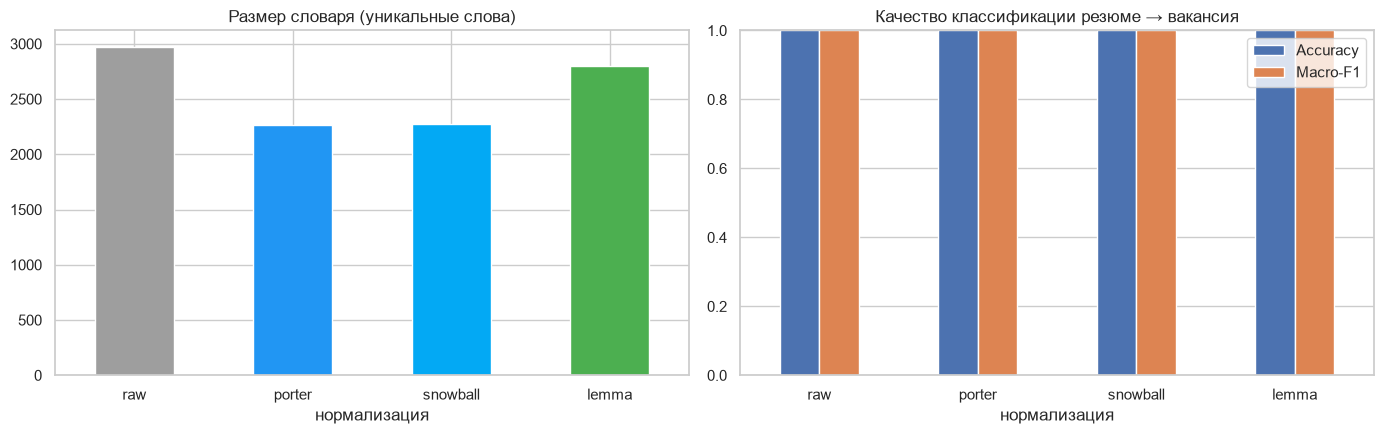

In [17]:
# влияние на качество: TF-IDF (1–2-граммы) + LinearSVC на train∩exp → test∩exp
from sklearn.svm import LinearSVC
split_v, label_v, exp_v = norm_rows["split"].to_numpy(), norm_rows["label"].to_numpy(), norm_rows["in_exp"].to_numpy()
m_train_all, m_train, m_test = split_v == "train", (split_v == "train") & exp_v, (split_v == "test") & exp_v
assert m_test.sum() > 0 and m_train.sum() > 0, "Нет резюме выбранных классов в train/test — измените MIN_PER_CLASS/MAX_CLASSES"

norm_eval = []
for name, lists in NORM.items():
    texts = np.array([" ".join(l) for l in lists], dtype=object)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=10000).fit(texts[m_train_all])
    clf = LinearSVC(C=1.0, class_weight="balanced", random_state=SEED).fit(vec.transform(texts[m_train]), label_v[m_train])
    pred = clf.predict(vec.transform(texts[m_test]))
    sc, ci = clf_scores(label_v[m_test], pred), bootstrap_ci(label_v[m_test], pred)
    norm_eval.append({"нормализация": name, "признаков": len(vec.vocabulary_), "Accuracy": sc["accuracy"],
                      "Acc 95% CI": f"[{ci['acc_ci'][0]:.3f}; {ci['acc_ci'][1]:.3f}]", "Macro-F1": sc["macro_f1"],
                      "F1 95% CI": f"[{ci['f1_ci'][0]:.3f}; {ci['f1_ci'][1]:.3f}]"})
norm_eval = pd.DataFrame(norm_eval).set_index("нормализация")
display(norm_eval.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
stats["типов (униграммы)"].plot(kind="bar", ax=axes[0], color=["#9E9E9E", "#2196F3", "#03A9F4", "#4CAF50"]); axes[0].set_title("Размер словаря (уникальные слова)"); axes[0].tick_params(axis="x", rotation=0)
norm_eval[["Accuracy", "Macro-F1"]].plot(kind="bar", ax=axes[1]); axes[1].set_title("Качество классификации резюме → вакансия"); axes[1].set_ylim(0, 1); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [18]:
# автоматические выводы (числа подставляются из этого запуска)
best_norm = norm_eval["Macro-F1"].idxmax()
f1_lo, f1_hi = [float(x) for x in norm_eval.loc[best_norm, "F1 95% CI"].strip("[]").split(";")]
others_inside = [n for n in norm_eval.index if n != best_norm and f1_lo <= norm_eval.loc[n, "Macro-F1"] <= f1_hi]
print("ВЫВОДЫ по нормализации (посчитаны в этом запуске):")
print(f"• Размер словаря: raw {stats.loc['raw','типов (униграммы)']} → lemma {stats.loc['lemma','типов (униграммы)']} "
      f"({stats.loc['lemma','сжатие словаря vs raw']:.0%}), Porter {stats.loc['porter','типов (униграммы)']} ({stats.loc['porter','сжатие словаря vs raw']:.0%}), "
      f"Snowball {stats.loc['snowball','типов (униграммы)']} ({stats.loc['snowball','сжатие словаря vs raw']:.0%}).")
print(f"• «Нечитаемые» формы (не встречаются как слова корпуса): Porter {stats.loc['porter'].iloc[-1]:.0%}, Snowball {stats.loc['snowball'].iloc[-1]:.0%}, лемматизация {stats.loc['lemma'].iloc[-1]:.0%}.")
print(f"• Названия технологий искажаются: Porter {tech.loc['Porter'].iloc[0]:.0%}, Snowball {tech.loc['Snowball'].iloc[0]:.0%}, лемматизатор {tech.loc['spaCy lemma'].iloc[0]:.0%} однословных навыков.")
print(f"• Скорость: стемминг ~{speed.loc['Porter (на готовых токенах)'].iloc[0] / speed.loc['spaCy: токенизация+теггер+лемматизатор'].iloc[0]:.0f}× быстрее полного spaCy-прохода на токен (но токенизацию стеммеру тоже нужно кому-то поручить).")
print(f"• Качество: лучший Macro-F1 у «{best_norm}» ({norm_eval.loc[best_norm,'Macro-F1']:.3f}); "
      + (f"ещё {others_inside} внутри его 95% CI → различия статистически неразличимы." if others_inside else "остальные варианты вне его 95% CI."))
max_dist = float(tech.iloc[:, 0].max())
print("\nРЕШЕНИЕ для проекта:")
if max_dist >= 0.05:
    print(f"  словарный поиск навыков (EntityRuler, LOWER) оставляем БЕЗ стемминга/лемматизации: нормализация меняет до {max_dist:.0%} названий технологий, "
          "и словарные паттерны перестали бы совпадать с текстом.")
else:
    print(f"  названия технологий почти не искажаются (макс. {max_dist:.0%}), но словарный поиск всё равно проще и надёжнее оставить на LOWER без нормализации.")
print("  Нормализацию стоит добавлять только в «мешочные» признаки (TF-IDF) и только если она улучшает Macro-F1 вне доверительного интервала "
      "(см. строку «Качество» выше); иначе выигрыш — лишь в размере словаря, а не в качестве.")

ВЫВОДЫ по нормализации (посчитаны в этом запуске):
• Размер словаря: raw 2972 → lemma 2795 (6%), Porter 2268 (24%), Snowball 2272 (24%).
• «Нечитаемые» формы (не встречаются как слова корпуса): Porter 46%, Snowball 44%, лемматизация 7%.
• Названия технологий искажаются: Porter 61%, Snowball 60%, лемматизатор 21% однословных навыков.
• Скорость: стемминг ~4× быстрее полного spaCy-прохода на токен (но токенизацию стеммеру тоже нужно кому-то поручить).
• Качество: лучший Macro-F1 у «raw» (1.000); ещё ['porter', 'snowball', 'lemma'] внутри его 95% CI → различия статистически неразличимы.

РЕШЕНИЕ для проекта:
  словарный поиск навыков (EntityRuler, LOWER) оставляем БЕЗ стемминга/лемматизации: нормализация меняет до 61% названий технологий, и словарные паттерны перестали бы совпадать с текстом.
  Нормализацию стоит добавлять только в «мешочные» признаки (TF-IDF) и только если она улучшает Macro-F1 вне доверительного интервала (см. строку «Качество» выше); иначе выигрыш — лишь в размере слов

## 9. Частотный анализ n-грамм (униграммы, биграммы, триграммы)
Корпус — резюме части `train` (нижний регистр; токенизатор сохраняет `c++`, `node.js`, `ci/cd`, `scikit-learn`). Стоп-слова **не** удаляются до построения n-грамм (иначе «experience in python» превращается в ложное «experience python»); вместо этого отбрасываются n-граммы, которые начинаются или заканчиваются стоп-словом. Частота считается двумя способами: **TF** (всего вхождений) и **DF** (в скольких резюме встречается) — для резюме DF надёжнее, потому что один кандидат может многократно повторять слово.

1-граммы: типов     3,285  | после фильтра стоп-слов     3,152  | вхождений    294,212
2-граммы: типов    15,098  | после фильтра стоп-слов    11,947  | вхождений    290,406
3-граммы: типов    22,293  | после фильтра стоп-слов    18,042  | вхождений    286,600


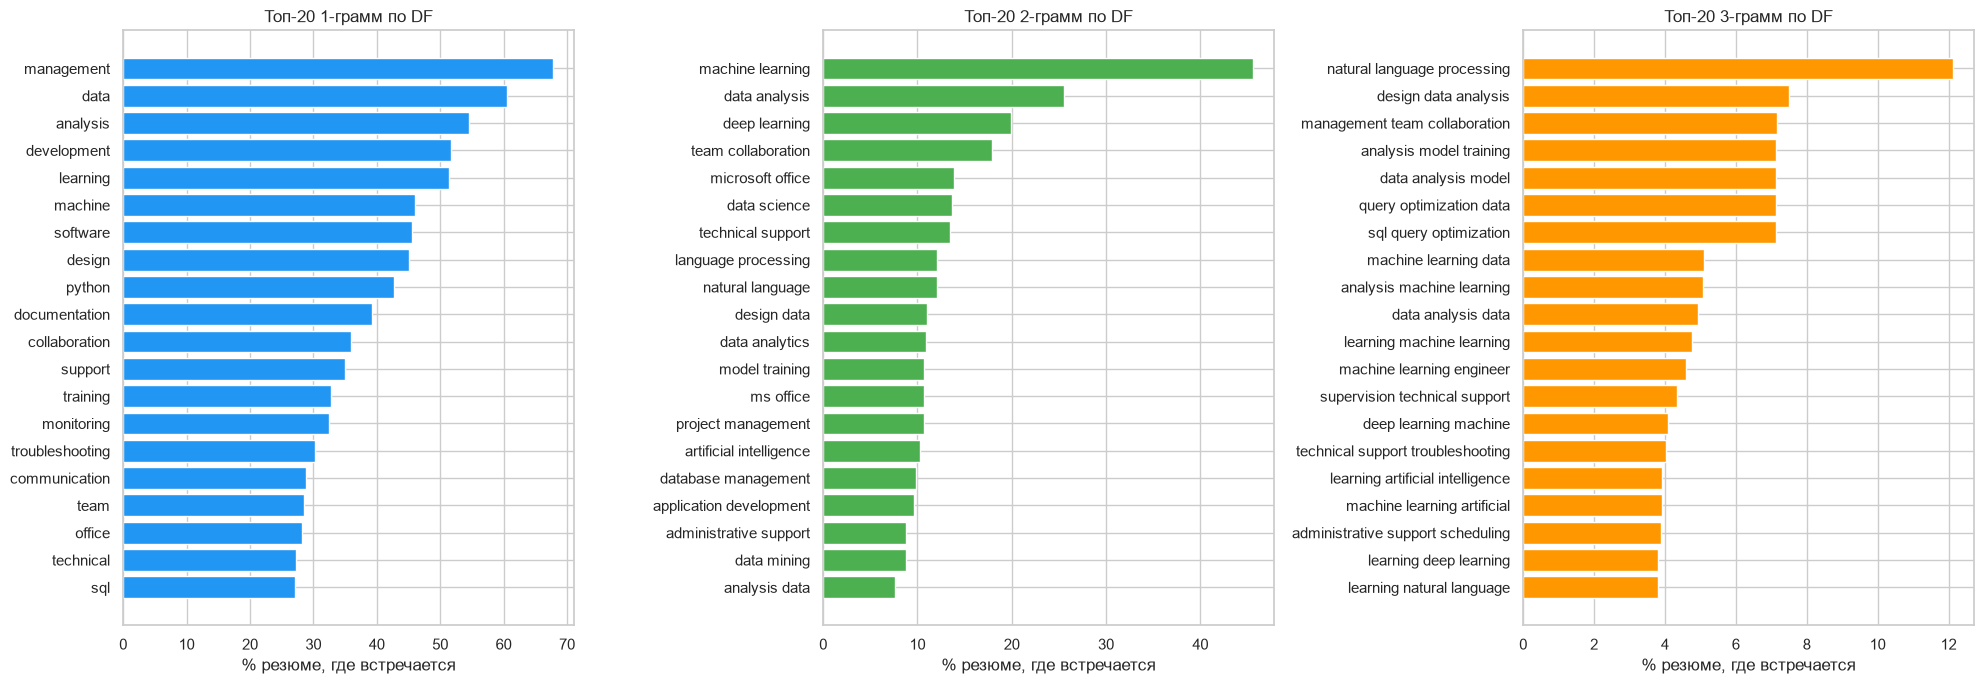

,n-грамма,DF (резюме),DF %,TF (вхождений),навык из словаря
0,machine learning,1733,45.5,2657,True
1,data analysis,973,25.6,1046,True
2,deep learning,760,20.0,873,True
3,team collaboration,680,17.9,680,True
4,data science,519,13.6,610,True
5,microsoft office,526,13.8,580,True
6,technical support,510,13.4,540,True
7,language processing,461,12.1,537,False
8,natural language,461,12.1,537,False
9,ms office,406,10.7,467,True


In [19]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP
TOKEN_PAT = r"(?u)[a-zA-Z][a-zA-Z0-9+#]*(?:[./\-][a-zA-Z0-9+#]+)*"
train_mask_ng = (df["split"] == "train").to_numpy()
ng_texts = df.loc[train_mask_ng, "resume_text"].str.lower().tolist()
ng_labels = df.loc[train_mask_ng, "label"].to_numpy(dtype=object)
SKILL_SET = VOCAB_SKILLS | CURATED

NG = {}
for n in (1, 2, 3):
    cv = CountVectorizer(ngram_range=(n, n), token_pattern=TOKEN_PAT, lowercase=True, dtype=np.int32)
    X = cv.fit_transform(ng_texts)
    terms = cv.get_feature_names_out()
    tf = np.asarray(X.sum(0)).ravel()
    dfc = np.asarray((X > 0).sum(0)).ravel()
    keep = np.array([not ({t.split()[0], t.split()[-1]} & STOP) for t in terms])
    NG[n] = dict(X=X, terms=terms, tf=tf, df=dfc, keep=keep)
    del cv
    print(f"{n}-граммы: типов {len(terms):>9,}  | после фильтра стоп-слов {keep.sum():>9,}  | вхождений {tf.sum():>10,}")
N_DOCS_NG = len(ng_texts)

def top_table(n, by="df", k=20):
    d = NG[n]
    idx = np.where(d["keep"])[0]
    idx = idx[np.argsort(-d[by][idx], kind="stable")][:k]
    return pd.DataFrame({"n-грамма": d["terms"][idx], "DF (резюме)": d["df"][idx], "DF %": 100 * d["df"][idx] / N_DOCS_NG,
                         "TF (вхождений)": d["tf"][idx], "навык из словаря": [t in SKILL_SET for t in d["terms"][idx]]})

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, n, color in zip(axes, (1, 2, 3), ("#2196F3", "#4CAF50", "#FF9800")):
    t = top_table(n, "df", 20)
    ax.barh(t["n-грамма"][::-1], t["DF %"][::-1], color=color)
    ax.set_title(f"Топ-20 {n}-грамм по DF"); ax.set_xlabel("% резюме, где встречается")
plt.tight_layout(); plt.show()
display(top_table(2, "tf", 15).round(1))

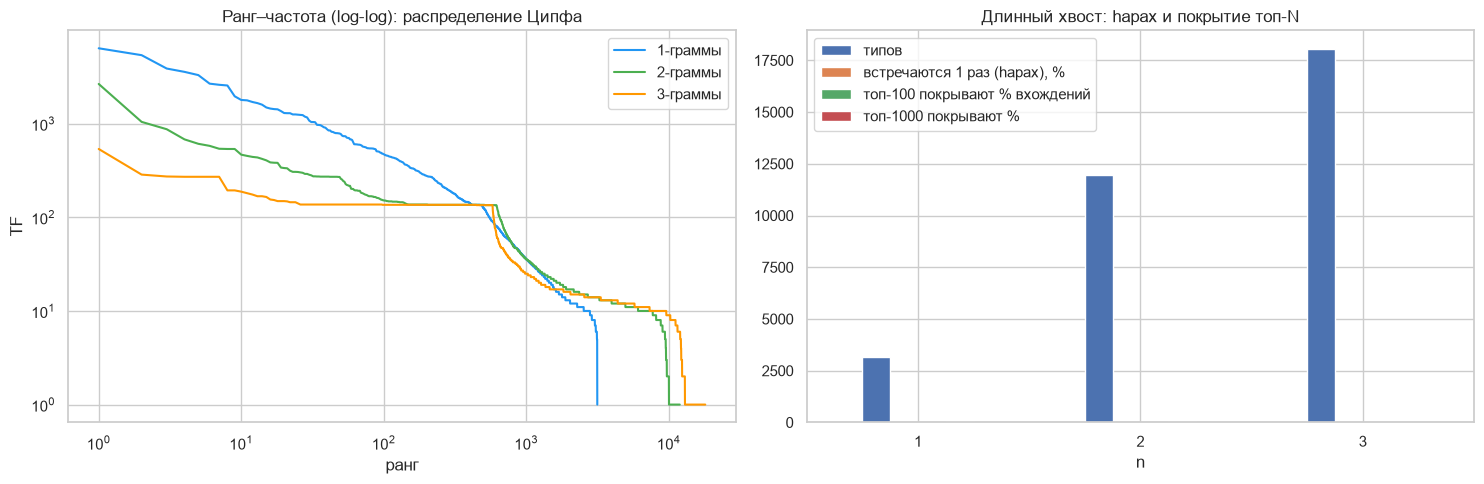

,типов,"встречаются 1 раз (hapax), %",топ-100 покрывают % вхождений,топ-1000 покрывают %
n,,,,
1,3152,0.1,41.5,87.7
2,11947,16.1,13.0,53.2
3,18042,28.1,6.6,42.1


In [20]:
# закон Ципфа (ранг–частота) и «длинный хвост»
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n, color in zip((1, 2, 3), ("#2196F3", "#4CAF50", "#FF9800")):
    d = NG[n]; f = np.sort(d["tf"][d["keep"]])[::-1]
    axes[0].loglog(np.arange(1, len(f) + 1), f, color=color, label=f"{n}-граммы")
axes[0].set_title("Ранг–частота (log-log): распределение Ципфа"); axes[0].set_xlabel("ранг"); axes[0].set_ylabel("TF"); axes[0].legend()

tail = []
for n in (1, 2, 3):
    d = NG[n]; f = np.sort(d["tf"][d["keep"]])[::-1]
    tail.append({"n": n, "типов": len(f), "встречаются 1 раз (hapax), %": 100 * (f == 1).mean(),
                 "топ-100 покрывают % вхождений": 100 * f[:100].sum() / f.sum(), "топ-1000 покрывают %": 100 * f[:1000].sum() / f.sum()})
tail = pd.DataFrame(tail).set_index("n")
tail.round(1).plot(kind="bar", ax=axes[1]); axes[1].set_title("Длинный хвост: hapax и покрытие топ-N"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
display(tail.round(1))

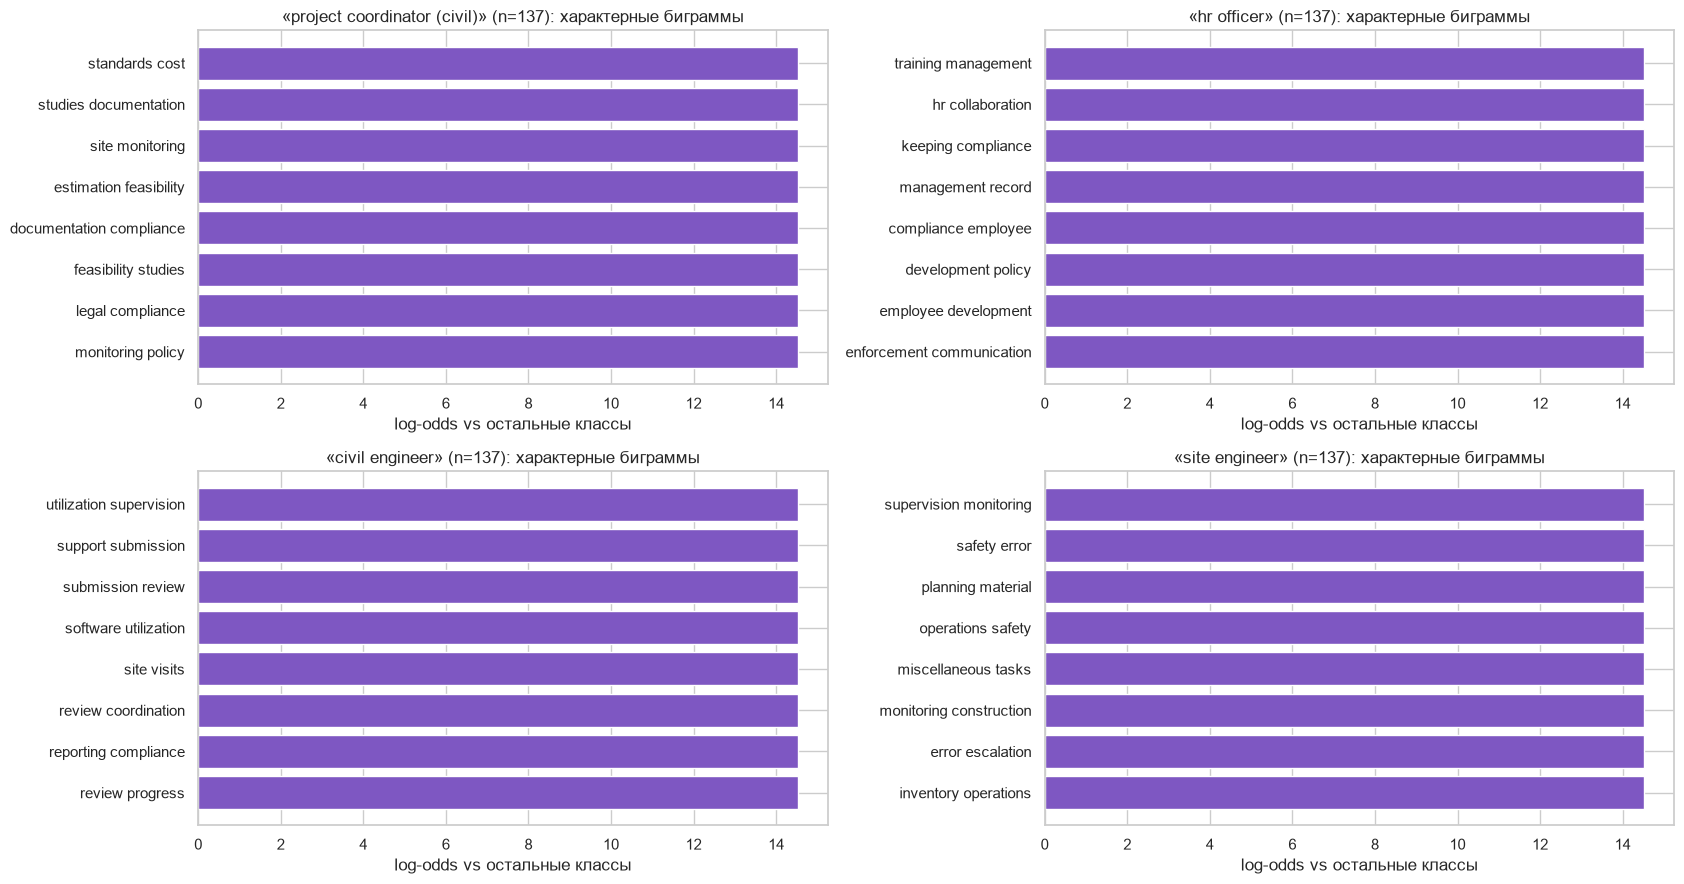

In [21]:
# характерные биграммы по классам (сглаженное log-odds, DF внутри класса vs остальные)
X2b = (NG[2]["X"] > 0).tocsr()
keep2, terms2 = NG[2]["keep"], NG[2]["terms"]
top_classes = [c for c, _ in Counter(l for l in ng_labels if l in CLASS_ID).most_common(4)]
fig, axes = plt.subplots(2, 2, figsize=(17, 9)); axes = axes.ravel()
distinct = {}
for ax, c in zip(axes, top_classes):
    m = ng_labels == c
    nc, nr = m.sum(), (~m).sum()
    dc = np.asarray(X2b[m].sum(0)).ravel(); dr = np.asarray(X2b[~m].sum(0)).ravel()
    a = 0.5
    lo = np.log((dc + a) / (nc - dc + a)) - np.log((dr + a) / (nr - dr + a))
    lo[~keep2 | (dc < 5)] = -np.inf
    idx = np.argsort(-lo)[:8]
    distinct[c] = [(terms2[i], int(dc[i]), int(dr[i])) for i in idx if np.isfinite(lo[i])]
    ax.barh([terms2[i] for i in idx][::-1], [lo[i] for i in idx][::-1], color="#7E57C2")
    ax.set_title(f"«{c}» (n={nc}): характерные биграммы"); ax.set_xlabel("log-odds vs остальные классы")
plt.tight_layout(); plt.show()

In [22]:
# PMI: «устойчивые словосочетания» против просто частых пар; повторы внутри резюме (TF/DF)
uni = dict(zip(NG[1]["terms"], NG[1]["tf"])); N1, N2 = NG[1]["tf"].sum(), NG[2]["tf"].sum()
b = NG[2]; sel = np.where(b["keep"] & (b["tf"] >= 15))[0]
pmi = np.array([np.log2((b["tf"][i] / N2) / ((uni.get(b["terms"][i].split()[0], 1) / N1) * (uni.get(b["terms"][i].split()[1], 1) / N1))) for i in sel])
pmi_tbl = pd.DataFrame({"биграмма": b["terms"][sel], "TF": b["tf"][sel], "PMI": pmi, "навык из словаря": [t in SKILL_SET for t in b["terms"][sel]]})
print("Топ-12 биграмм по PMI (TF >= 15):"); display(pmi_tbl.sort_values("PMI", ascending=False).head(12).round(2).reset_index(drop=True))

u = NG[1]; sel1 = np.where(u["keep"] & (u["df"] >= 20))[0]
rep = pd.DataFrame({"слово": u["terms"][sel1], "TF": u["tf"][sel1], "DF": u["df"][sel1], "TF/DF": u["tf"][sel1] / u["df"][sel1]})
print("\nСлова, которые резюме повторяют чаще всего (высокий TF/DF):"); display(rep.sort_values("TF/DF", ascending=False).head(8).round(2).reset_index(drop=True))

Топ-12 биграмм по PMI (TF >= 15):


,биграмма,TF,PMI,навык из словаря
0,train employees,15,14.28,True
1,leetcode gdb,15,14.28,False
2,ibm-pc copier,15,14.28,False
3,include wds,15,14.28,False
4,improved deliveries,15,14.28,False
5,owasp zap,15,14.28,True
6,offset unusual,15,14.28,False
7,mediasource factiva,15,14.28,False
8,macintosh mainframe,15,14.28,False
9,wds syteline,15,14.28,False



Слова, которые резюме повторяют чаще всего (высокий TF/DF):


,слово,TF,DF,TF/DF
0,vat,680,136,5.00
1,trained,81,21,3.86
2,verification,816,272,3.00
3,skill,114,39,2.92
4,data,6391,2303,2.78
5,financial,1295,508,2.55
6,mortgage,51,21,2.43
7,test,379,172,2.20


In [23]:
# автоматическая интерпретация (числа из этого запуска)
t1, t2, t3 = top_table(1, "df", 30), top_table(2, "df", 30), top_table(3, "df", 30)
print("ИНТЕРПРЕТАЦИЯ:")
for n, t in ((1, t1), (2, t2), (3, t3)):
    sk = t["навык из словаря"].mean()
    generic = t.loc[~t["навык из словаря"], "n-грамма"].head(6).tolist()
    print(f"• {n}-граммы: среди топ-30 по DF {sk:.0%} — навыки из словаря; остальное — общие/служебные обороты: {generic}")
h = [tail.loc[n, 'встречаются 1 раз (hapax), %'] for n in (1, 2, 3)]
print(f"• Распределение Ципфа: доля n-грамм, встречающихся ровно один раз (hapax): {h[0]:.0f}% (униграммы) → {h[1]:.0f}% (биграммы) → {h[2]:.0f}% (триграммы). "
      "Чем длиннее n-грамма, тем разреженнее признак — это довод за ограничение (1,2) и за порог min_df в TF-IDF.")
print(f"• Топ-100 биграмм покрывают лишь {tail.loc[2, 'топ-100 покрывают % вхождений']:.0f}% всех вхождений: словарь навыков в тексте тоже имеет длинный хвост → EntityRuler с фиксированным словарём всегда будет упираться в OOV.")
hi_pmi = pmi_tbl.sort_values("PMI", ascending=False).head(12)
print(f"• Среди 12 биграмм с наибольшим PMI навыками из словаря являются {hi_pmi['навык из словаря'].mean():.0%}; "
      "PMI сильнее выделяет устойчивые словосочетания, чем чистая частота (сравните с таблицей топ-биграмм по TF выше).")
for c, lst in distinct.items():
    print(f"• «{c}»: " + ", ".join(t for t, _, _ in lst[:5]))
print("  Если характерные n-граммы класса — профессиональные термины, то класс отделяется по лексике (линейные модели на TF-IDF справятся); "
      "если среди них много общих фраз, различия между классами слабые — это объясняет путаницу в разделе «Разбор ошибок».")

ИНТЕРПРЕТАЦИЯ:
• 1-граммы: среди топ-30 по DF 73% — навыки из словаря; остальное — общие/служебные обороты: ['data', 'learning', 'machine', 'monitoring', 'team', 'technical']
• 2-граммы: среди топ-30 по DF 67% — навыки из словаря; остальное — общие/служебные обороты: ['language processing', 'natural language', 'design data', 'model training', 'analysis data', 'policy development']
• 3-граммы: среди топ-30 по DF 7% — навыки из словаря; остальное — общие/служебные обороты: ['design data analysis', 'management team collaboration', 'analysis model training', 'data analysis model', 'query optimization data', 'sql query optimization']
• Распределение Ципфа: доля n-грамм, встречающихся ровно один раз (hapax): 0% (униграммы) → 16% (биграммы) → 28% (триграммы). Чем длиннее n-грамма, тем разреженнее признак — это довод за ограничение (1,2) и за порог min_df в TF-IDF.
• Топ-100 биграмм покрывают лишь 13% всех вхождений: словарь навыков в тексте тоже имеет длинный хвост → EntityRuler с фиксированн

## 10. Сравнение представлений: baseline, Bag-of-Words, TF-IDF, эмбеддинги
Один и тот же датасет, одно разбиение, один и тот же классификатор (LinearSVC, `C` подбирается 3-fold CV на `train`) и один и тот же эталон — название вакансии.

| Представление | Описание |
|---|---|
| **Baseline** | самый частый класс (классификация) / случайный порядок (поиск) |
| **Skill-overlap** | бинарный вектор навыков, найденных EntityRuler; для поиска — формула продукта (доля навыков вакансии, найденных в резюме) |
| **BoW** | CountVectorizer (1–2-граммы, стоп-слова, 10 000 признаков), L2-нормировка счётчиков |
| **TF-IDF** | тот самый векторизатор, что сохраняется в `tfidf.pkl` (обучен на всех резюме `train`) |
| **spaCy-эмбеддинги** | среднее статических векторов `en_core_web_md` (300-d) по значимым словам |
| **Sentence-BERT** | `all-MiniLM-L6-v2` (если установлен `sentence-transformers` и есть доступ к модели; иначе пропускается) |

**Две постановки на одних и тех же данных.**
* *Классификация*: резюме → название вакансии. Метрики: Accuracy, Macro-F1 (+ 95% bootstrap CI).
* *Поиск*: запрос — резюме из `test`, коллекция — уникальные вакансии из `test`; релевантны вакансии с тем же названием. Метрики: Precision@1/5/10, MRR.

**Ресурсы**: время обучения/кодирования (с), задержка на документ (мс), пик памяти Python (`tracemalloc`, MB), прирост RSS процесса (MB), размер признаков и модели.

In [24]:
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV

tr = df[(df["split"] == "train") & df["in_exp"]]
te = df[(df["split"] == "test") & df["in_exp"]]
assert len(tr) and len(te), "Нет резюме выбранных классов в train/test — измените MIN_PER_CLASS/MAX_CLASSES"
y_tr, y_te = tr["label"].to_numpy(dtype=object), te["label"].to_numpy(dtype=object)
fit_texts, tr_texts, te_texts = train_texts_all, tr["resume_text"].tolist(), te["resume_text"].tolist()

pool = te.drop_duplicates(["job_text", "label"])
pool_texts, pool_labels = pool["job_text"].tolist(), pool["label"].to_numpy(dtype=object)
_pidx = {(t, l): i for i, (t, l) in enumerate(zip(pool["job_text"], pool["label"]))}
own_idx = np.array([_pidx[(t, l)] for t, l in zip(te["job_text"], te["label"])])
REL = y_te[:, None] == pool_labels[None, :]
print(f"train (классификатор): {len(tr)} | test: {len(te)} | коллекция вакансий: {len(pool)} | классов: {K} "
      f"| релевантных вакансий на запрос в среднем: {REL.sum(1).mean():.1f}")

train (классификатор): 3806 | test: 1904 | коллекция вакансий: 28 | классов: 28 | релевантных вакансий на запрос в среднем: 1.0


In [25]:
class SparseRep:
    kind = "sparse"
    def __init__(self, name, make, l2=False, trace=True):
        self.name, self.make, self.l2, self.trace = name, make, l2, trace
    def fit(self, texts):
        self.v = self.make().fit(texts); return self
    def encode(self, texts):
        X = self.v.transform(texts)
        return sk_normalize(X) if self.l2 else X
    def similarity(self, Xq, Xp):
        return cosine_similarity(Xq, Xp)
    def dim(self): return len(self.v.vocabulary_)
    def model_mb(self):
        if hasattr(self.v, "stop_words_"):
            self.v.stop_words_ = None          # служебный атрибут: список отброшенных термов, сильно раздувает pickle
        return len(pickle.dumps(self.v)) / 2**20

class SpacyMeanRep:
    kind = "dense"
    def __init__(self, name="spaCy-эмбеддинги (en_core_web_md, mean)", trace=True):
        self.name, self.trace = name, trace
        self.nlp = spacy.load(SPACY_MODEL, exclude=["tok2vec", "tagger", "parser", "attribute_ruler", "lemmatizer", "ner"])
        self._dim = self.nlp.vocab.vectors_length
    def fit(self, texts): return self
    def encode(self, texts):
        out = np.zeros((len(texts), self._dim), dtype=np.float32)
        for i, doc in enumerate(self.nlp.pipe(texts, batch_size=64)):
            vs = [t.vector for t in doc if t.is_alpha and not t.is_stop and t.has_vector]
            if vs:
                out[i] = np.mean(vs, axis=0)
        n = np.linalg.norm(out, axis=1, keepdims=True); n[n == 0] = 1
        return out / n
    def similarity(self, Xq, Xp): return Xq @ Xp.T
    def dim(self): return self._dim
    def model_mb(self): return self.nlp.vocab.vectors.data.nbytes / 2**20

class SBERTRep:
    kind = "dense"
    def __init__(self, model, name="Sentence-BERT (all-MiniLM-L6-v2)", trace=False):
        self.m, self.name, self.trace = model, name, trace      # trace=False: tracemalloc не видит память torch → смотрим RSS
    def fit(self, texts): return self
    def encode(self, texts):
        return np.asarray(self.m.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False), dtype=np.float32)
    def similarity(self, Xq, Xp): return Xq @ Xp.T
    def dim(self): return self.m.get_sentence_embedding_dimension()
    def model_mb(self):
        try: return sum(p.numel() * p.element_size() for p in self.m.parameters()) / 2**20
        except Exception: return float("nan")

class SkillSetsRep:
    kind = "sparse"
    def __init__(self, nlp_ner, vocab, name="Skill-overlap (NER → бинарные навыки)", trace=True):
        self.nlp, self.name, self.trace = nlp_ner, name, trace
        self.index = {s: i for i, s in enumerate(sorted(vocab))}
        self.unknown = 0
    def fit(self, texts): return self
    def encode(self, texts):
        rows, cols = [], []
        for i, s in enumerate(predict_skills(self.nlp, texts)):
            for sk in s:
                j = self.index.get(sk)
                if j is None:
                    self.unknown += 1; continue
                rows.append(i); cols.append(j)
        return csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(texts), len(self.index)))
    def similarity(self, Xq, Xp):                 # как в продукте: доля навыков вакансии, найденных у кандидата
        inter = (Xq @ Xp.T).toarray()
        need = np.asarray(Xp.sum(1)).ravel()
        return inter / np.maximum(need, 1)[None, :]
    def dim(self): return len(self.index)
    def model_mb(self): return len(pickle.dumps(self.index)) / 2**20

reps = [
    SkillSetsRep(nlp_eval, pattern_skills),
    SparseRep("BoW (counts, 1–2-граммы)", lambda: CountVectorizer(ngram_range=(1, 2), stop_words="english", max_features=10000), l2=True),
    SparseRep("TF-IDF (1–2-граммы, sublinear)", lambda: TfidfVectorizer(**TFIDF_PARAMS)),
    SpacyMeanRep(),
]
sbert_rep = None
if USE_SBERT != "0":
    try:
        from sentence_transformers import SentenceTransformer
        sbert_rep = SBERTRep(SentenceTransformer(SBERT_MODEL))
        reps.append(sbert_rep)
    except Exception as exc:
        if USE_SBERT == "1":
            raise
        print("Sentence-BERT пропущен (нет пакета или доступа к модели):", repr(exc)[:150])

Sentence-BERT пропущен (нет пакета или доступа к модели): ModuleNotFoundError("No module named 'sentence_transformers'")


In [26]:
def encode_stage(rep):
    out = {}
    t = time.perf_counter(); rep.fit(fit_texts);               out["t_fit"] = time.perf_counter() - t
    t = time.perf_counter(); out["Xtr"] = rep.encode(tr_texts); out["t_enc_tr"] = time.perf_counter() - t
    t = time.perf_counter(); out["Xte"] = rep.encode(te_texts); out["t_enc_te"] = time.perf_counter() - t
    t = time.perf_counter(); out["Xp"]  = rep.encode(pool_texts); out["t_enc_pool"] = time.perf_counter() - t
    return out

def clf_stage(Xtr, Xte, tune=True):
    if not tune:
        t = time.perf_counter(); m = DummyClassifier(strategy="most_frequent").fit(Xtr, y_tr); t_clf = time.perf_counter() - t
        t = time.perf_counter(); pred = m.predict(Xte); return pred, None, m.classes_, t_clf, time.perf_counter() - t, None
    min_cls = Counter(y_tr).most_common()[-1][1]
    gs = GridSearchCV(LinearSVC(class_weight="balanced", max_iter=5000, random_state=SEED), {"C": [0.1, 1, 10]},
                      cv=max(2, min(3, min_cls)), scoring="f1_macro")
    t = time.perf_counter(); gs.fit(Xtr, y_tr); t_clf = time.perf_counter() - t
    t = time.perf_counter(); pred = gs.predict(Xte); dec = gs.decision_function(Xte); t_pred = time.perf_counter() - t
    return pred, dec, gs.classes_, t_clf, t_pred, gs.best_params_["C"]

results = {}
def run(rep):
    stage, t_total, peak_mb, drss = profile_run(lambda: encode_stage(rep), trace=rep.trace)
    Xtr, Xte, Xp = stage["Xtr"], stage["Xte"], stage["Xp"]
    pred, dec, classes_, t_clf, t_pred, bestC = clf_stage(Xtr, Xte)
    S = rep.similarity(Xte, Xp)
    if isinstance(rep, SkillSetsRep):                                   # случайно разрешаем ничьи (у формулы продукта их много)
        S = S + np.random.default_rng(SEED).random(S.shape) * 1e-6
    sc, ci = clf_scores(y_te, pred), bootstrap_ci(y_te, pred)
    ret = retrieval_metrics(S, REL)
    results[rep.name] = dict(
        accuracy=sc["accuracy"], macro_f1=sc["macro_f1"], acc_ci=ci["acc_ci"], f1_ci=ci["f1_ci"], **ret,
        fit_s=stage["t_fit"], encode_s=stage["t_enc_tr"] + stage["t_enc_te"], clf_train_s=t_clf,
        latency_ms=1000 * (stage["t_enc_te"] / len(te_texts) + t_pred / len(te_texts)),
        peak_py_mb=peak_mb, d_rss_mb=drss, feat_mb=sum(sparse_mb(x) for x in (Xtr, Xte, Xp)),
        model_mb=rep.model_mb(), dim=rep.dim(), best_C=bestC, pred=pred, dec=dec, classes=classes_,
        own_sim=S[np.arange(len(te)), own_idx], Xtr=Xtr if "TF-IDF" in rep.name else None)
    print(f"✓ {rep.name}: Acc={sc['accuracy']:.3f} MacroF1={sc['macro_f1']:.3f} P@5={ret['P@5']:.3f} MRR={ret['MRR']:.3f} | "
          f"кодирование {results[rep.name]['encode_s']:.1f} с, обучение {t_clf:.1f} с")

for rep in reps:
    run(rep)

# baseline: самый частый класс + случайный порядок
rs = np.random.default_rng(SEED)
pred_d, _, _, t_d, _, _ = clf_stage(np.zeros((len(tr), 1)), np.zeros((len(te), 1)), tune=False)
sc_d, ci_d = clf_scores(y_te, pred_d), bootstrap_ci(y_te, pred_d)
ret_d = retrieval_metrics(rs.random((len(te), len(pool))), REL)
results["Baseline (мажоритарный класс / случайный порядок)"] = dict(
    accuracy=sc_d["accuracy"], macro_f1=sc_d["macro_f1"], acc_ci=ci_d["acc_ci"], f1_ci=ci_d["f1_ci"], **ret_d,
    fit_s=0.0, encode_s=0.0, clf_train_s=t_d, latency_ms=0.0, peak_py_mb=0.0, d_rss_mb=0.0, feat_mb=0.0, model_mb=0.0, dim=0,
    best_C=None, pred=pred_d, dec=None, classes=None, own_sim=None, Xtr=None)

_sk = next(r for r in reps if isinstance(r, SkillSetsRep))
print(f"\nНавыков, найденных NER, но отсутствующих в индексе признаков: {_sk.unknown} (должно быть ~0)")
_tf = next(r for r in reps if "TF-IDF" in r.name)
assert _tf.v.vocabulary_ == matcher.vectorizer.vocabulary_, "оцениваемый TF-IDF отличается от сохраняемого"
print("✓ Оцениваемый TF-IDF идентичен matcher.vectorizer (тому, что будет сохранён в tfidf.pkl)")

✓ Skill-overlap (NER → бинарные навыки): Acc=1.000 MacroF1=1.000 P@5=0.200 MRR=0.996 | кодирование 57.1 с, обучение 3.2 с
✓ BoW (counts, 1–2-граммы): Acc=1.000 MacroF1=1.000 P@5=0.200 MRR=0.992 | кодирование 0.7 с, обучение 3.7 с
✓ TF-IDF (1–2-граммы, sublinear): Acc=1.000 MacroF1=1.000 P@5=0.200 MRR=1.000 | кодирование 0.7 с, обучение 4.6 с
✓ spaCy-эмбеддинги (en_core_web_md, mean): Acc=0.994 MacroF1=0.994 P@5=0.136 MRR=0.503 | кодирование 2.1 с, обучение 15.7 с

Навыков, найденных NER, но отсутствующих в индексе признаков: 0 (должно быть ~0)
✓ Оцениваемый TF-IDF идентичен matcher.vectorizer (тому, что будет сохранён в tfidf.pkl)


In [27]:
cols = ["accuracy", "macro_f1", "P@1", "P@5", "P@10", "MRR", "fit_s", "encode_s", "clf_train_s", "latency_ms", "peak_py_mb", "d_rss_mb", "feat_mb", "model_mb", "dim"]
res_df = pd.DataFrame({k: {c: v[c] for c in cols} for k, v in results.items()}).T
res_df.columns = ["Accuracy", "Macro-F1", "P@1", "P@5", "P@10", "MRR", "fit, с", "encode train+test, с", "обучение clf, с",
                  "латентность, мс/док", "пик Python, MB", "ΔRSS, MB", "признаки, MB", "модель, MB", "размерность"]
res_df["Acc 95% CI"] = [f"[{v['acc_ci'][0]:.3f}; {v['acc_ci'][1]:.3f}]" for v in results.values()]
res_df["F1 95% CI"] = [f"[{v['f1_ci'][0]:.3f}; {v['f1_ci'][1]:.3f}]" for v in results.values()]
pd.set_option("display.width", 250, "display.max_columns", 30)
print("КАЧЕСТВО"); display(res_df[["Accuracy", "Acc 95% CI", "Macro-F1", "F1 95% CI", "P@1", "P@5", "P@10", "MRR"]].astype({c: float for c in ["Accuracy", "Macro-F1", "P@1", "P@5", "P@10", "MRR"]}).round(3))
print("РЕСУРСЫ"); display(res_df[["fit, с", "encode train+test, с", "обучение clf, с", "латентность, мс/док", "пик Python, MB", "ΔRSS, MB", "признаки, MB", "модель, MB", "размерность"]].astype(float).round(2))

КАЧЕСТВО


,Accuracy,Acc 95% CI,Macro-F1,F1 95% CI,P@1,P@5,P@10,MRR
Skill-overlap (NER → бинарные навыки),1.000,[1.000; 1.000],1.000,[1.000; 1.000],0.993,0.200,0.100,0.996
"BoW (counts, 1–2-граммы)",1.000,[1.000; 1.000],1.000,[1.000; 1.000],0.984,0.200,0.100,0.992
"TF-IDF (1–2-граммы, sublinear)",1.000,[1.000; 1.000],1.000,[1.000; 1.000],1.000,0.200,0.100,1.000
"spaCy-эмбеддинги (en_core_web_md, mean)",0.994,[0.990; 0.997],0.994,[0.990; 0.997],0.348,0.136,0.086,0.503
Baseline (мажоритарный класс / случайный порядок),0.036,[0.028; 0.045],0.002,[0.002; 0.003],0.040,0.037,0.038,0.145


РЕСУРСЫ


,"fit, с","encode train+test, с","обучение clf, с","латентность, мс/док","пик Python, MB","ΔRSS, MB","признаки, MB","модель, MB",размерность
Skill-overlap (NER → бинарные навыки),0.00,57.09,3.19,9.94,17.05,12.11,1.46,0.09,3960.0
"BoW (counts, 1–2-граммы)",0.43,0.65,3.75,0.12,14.11,6.94,7.38,0.34,10000.0
"TF-IDF (1–2-граммы, sublinear)",0.45,0.67,4.61,0.12,14.11,-16.59,7.38,0.42,10000.0
"spaCy-эмбеддинги (en_core_web_md, mean)",0.00,2.13,15.67,0.34,8.78,6.74,6.57,22.89,300.0
Baseline (мажоритарный класс / случайный порядок),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0


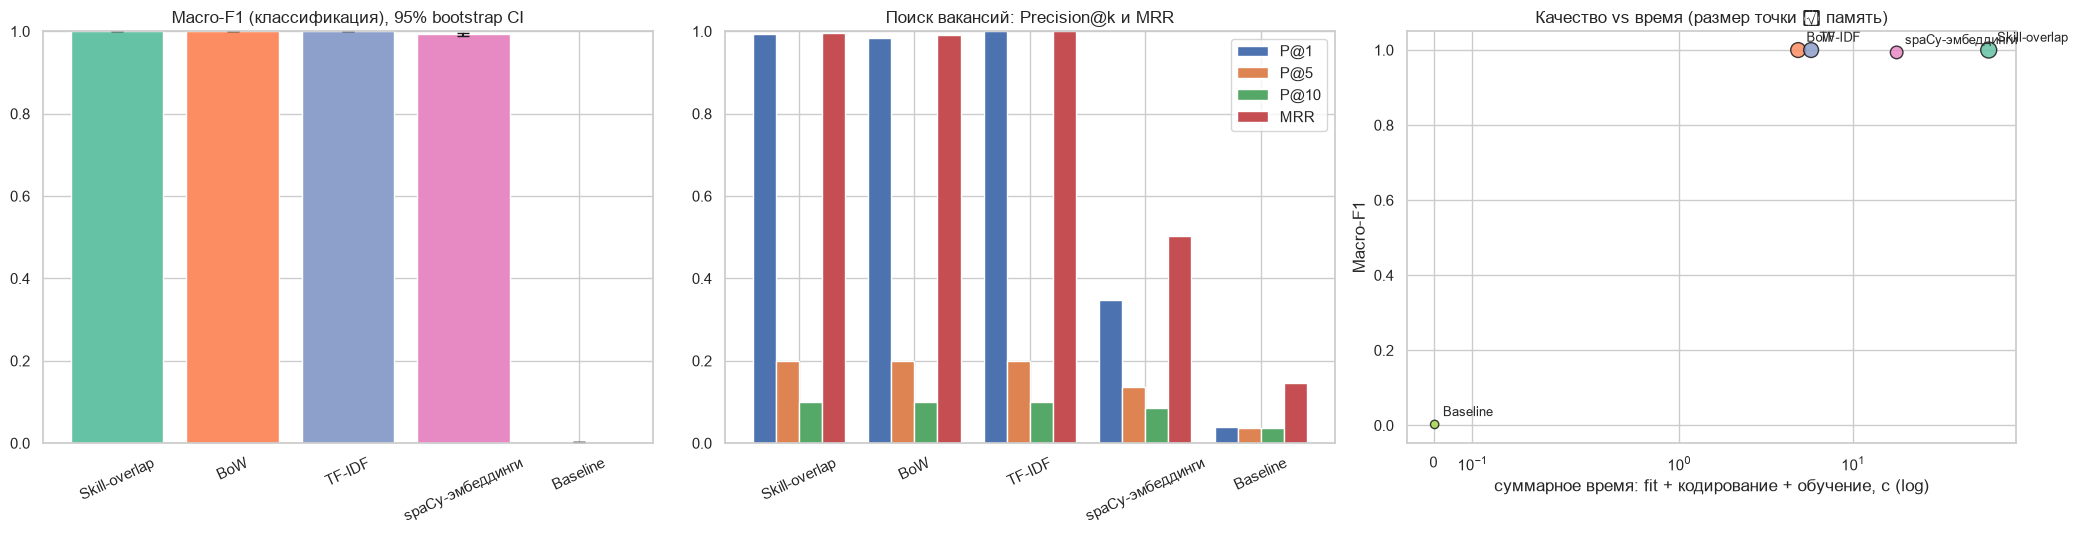

In [28]:
names = [n for n in results]
short = [n.split(" (")[0] for n in names]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
f1 = [results[n]["macro_f1"] for n in names]
err = np.array([[results[n]["macro_f1"] - results[n]["f1_ci"][0], results[n]["f1_ci"][1] - results[n]["macro_f1"]] for n in names]).T
axes[0].bar(short, f1, yerr=np.clip(err, 0, None), capsize=4, color=sns.color_palette("Set2", len(names)))
axes[0].set_title("Macro-F1 (классификация), 95% bootstrap CI"); axes[0].set_ylim(0, 1); axes[0].tick_params(axis="x", rotation=25)

w = 0.2
for j, mtr in enumerate(["P@1", "P@5", "P@10", "MRR"]):
    axes[1].bar(np.arange(len(names)) + j * w, [results[n][mtr] for n in names], w, label=mtr)
axes[1].set_xticks(np.arange(len(names)) + 1.5 * w); axes[1].set_xticklabels(short, rotation=25); axes[1].set_ylim(0, 1)
axes[1].set_title("Поиск вакансий: Precision@k и MRR"); axes[1].legend()

tot_t = [results[n]["fit_s"] + results[n]["encode_s"] + results[n]["clf_train_s"] for n in names]
mem = [max(results[n]["peak_py_mb"] or 0, results[n]["d_rss_mb"] or 0, 1) for n in names]
axes[2].scatter(tot_t, f1, s=[30 + 6 * m for m in mem], c=sns.color_palette("Set2", len(names)), edgecolor="k", alpha=0.85)
for x, y, s in zip(tot_t, f1, short):
    axes[2].annotate(s, (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
axes[2].set_xscale("symlog", linthresh=0.5); axes[2].set_xlabel("суммарное время: fit + кодирование + обучение, с (log)"); axes[2].set_ylabel("Macro-F1")
axes[2].set_title("Качество vs время (размер точки ∝ память)")
plt.tight_layout(); plt.show()

In [29]:
# корреляция сходства «резюме — своя вакансия» с matched_score из датасета (ещё одна независимая разметка)
ms = te["matched_score"].to_numpy()
ok = ~np.isnan(ms)
corr_rows = {}
for n, r in results.items():
    if r["own_sim"] is not None:
        corr_rows[n.split(" (")[0]] = spearmanr(r["own_sim"][ok], ms[ok])
tf_name = next(n for n in results if "TF-IDF" in n); sk_name = next(n for n in results if "Skill-overlap" in n)
final_own = 0.6 * results[sk_name]["own_sim"] + 0.4 * results[tf_name]["own_sim"]       # формула продукта
corr_rows["Итоговый балл продукта (0.6·overlap + 0.4·TF-IDF)"] = spearmanr(final_own[ok], ms[ok])
corr = pd.DataFrame({k: {"Spearman ρ": v.statistic, "p-value": v.pvalue} for k, v in corr_rows.items()}).T
display(corr.round(4))
print(f"(n = {ok.sum()} пар «резюме — своя вакансия» из test; matched_score — оценка из самого датасета, её природа неизвестна, поэтому это дополнительная, а не главная метрика)")

,Spearman ρ,p-value
Skill-overlap,0.1853,0.0000
BoW,0.1372,0.0000
TF-IDF,0.0480,0.0362
spaCy-эмбеддинги,0.2445,0.0000
Итоговый балл продукта (0.6·overlap + 0.4·TF-IDF),0.1605,0.0000


(n = 1904 пар «резюме — своя вакансия» из test; matched_score — оценка из самого датасета, её природа неизвестна, поэтому это дополнительная, а не главная метрика)


In [30]:
# автоматические выводы
cls = {n: r for n, r in results.items() if not n.startswith("Baseline")}
best_f1 = max(cls, key=lambda n: cls[n]["macro_f1"]); best_mrr = max(cls, key=lambda n: cls[n]["MRR"])
fast = min(cls, key=lambda n: cls[n]["fit_s"] + cls[n]["encode_s"] + cls[n]["clf_train_s"])
base = results["Baseline (мажоритарный класс / случайный порядок)"]
lo, hi = cls[best_f1]["f1_ci"]
tie = [n for n in cls if n != best_f1 and lo <= cls[n]["macro_f1"] <= hi]
print("ВЫВОДЫ по сравнению представлений (посчитаны в этом запуске):")
print(f"• Классификация: лучший Macro-F1 — «{best_f1}» ({cls[best_f1]['macro_f1']:.3f}, Accuracy {cls[best_f1]['accuracy']:.3f}); baseline: Accuracy {base['accuracy']:.3f}, Macro-F1 {base['macro_f1']:.3f}.")
print("  Статистически неотличимы от лучшего (Macro-F1 внутри его 95% CI): " + (", ".join(t.split(" (")[0] for t in tie) if tie else "нет — лидер отрывается"))
print(f"• Поиск вакансий: лучший MRR — «{best_mrr}» (MRR {cls[best_mrr]['MRR']:.3f}, P@5 {cls[best_mrr]['P@5']:.3f}); случайный порядок: MRR {base['MRR']:.3f}, P@5 {base['P@5']:.3f}.")
print(f"• Быстрее всего (fit+кодирование+обучение): «{fast}» — {cls[fast]['fit_s'] + cls[fast]['encode_s'] + cls[fast]['clf_train_s']:.1f} с.")
print(f"• Память (пик Python / модель): " + "; ".join(f"{n.split(' (')[0]}: {(r['peak_py_mb'] or 0):.0f}/{r['model_mb']:.1f} MB" for n, r in cls.items()))
if cls[best_f1]["accuracy"] < 1.5 * base["accuracy"]:
    print("⚠ Лучший Accuracy меньше чем в 1.5 раза выше мажоритарного baseline: целевая метка слабо предсказуема по тексту резюме "
          "(возможно, пары «резюме — вакансия» в датасете составлены почти случайно). Выбор «лучшего» представления в этом случае ненадёжен.")

ВЫВОДЫ по сравнению представлений (посчитаны в этом запуске):
• Классификация: лучший Macro-F1 — «Skill-overlap (NER → бинарные навыки)» (1.000, Accuracy 1.000); baseline: Accuracy 0.036, Macro-F1 0.002.
  Статистически неотличимы от лучшего (Macro-F1 внутри его 95% CI): BoW, TF-IDF
• Поиск вакансий: лучший MRR — «TF-IDF (1–2-граммы, sublinear)» (MRR 1.000, P@5 0.200); случайный порядок: MRR 0.145, P@5 0.037.
• Быстрее всего (fit+кодирование+обучение): «BoW (counts, 1–2-граммы)» — 4.8 с.
• Память (пик Python / модель): Skill-overlap: 17/0.1 MB; BoW: 14/0.3 MB; TF-IDF: 14/0.4 MB; spaCy-эмбеддинги: 9/22.9 MB


## 10b. Диагностика: почему качество ≈ 100%?
Если метрики равны 1.0 у *всех* представлений, включая самые примитивные (бинарные навыки, мешок слов), то это сигнал не о силе моделей, а о том, что **задача тривиальна или есть утечка**. Ниже — проверки, которые показывают, что именно происходит в данных:
1. сколько резюме и сколько разных текстов вакансий приходится на один класс;
2. есть ли почти-дубликаты резюме между `train` и `test` (точные дубликаты мы уже удалили — почти-дубликаты нет);
3. какое **поле** резюме по отдельности уже даёт ~100% (где «спрятана» метка);
4. упоминается ли название вакансии прямо в тексте резюме.

In [31]:
exp_all = df[df["in_exp"]]
sizes = exp_all.groupby("label").size()
jobs_per_label = exp_all.groupby("label")["job_text"].nunique()
print(f"1) Классов: {len(sizes)} | резюме на класс: min {sizes.min()}, медиана {int(sizes.median())}, max {sizes.max()} "
      f"({'ВСЕ КЛАССЫ ОДИНАКОВОГО РАЗМЕРА' if sizes.nunique() == 1 else 'размеры разные'})")
print(f"   Разных текстов вакансии на класс: min {jobs_per_label.min()}, max {jobs_per_label.max()} "
      f"→ релевантных вакансий на запрос в среднем {REL.sum(1).mean():.2f}"
      + ("  (=1: каждое название — это ровно ОДНА вакансия, метка = идентификатор вакансии; P@5 не может быть выше 0.2, P@10 — выше 0.1)" if REL.sum(1).mean() <= 1.05 else ""))

# 2) почти-дубликаты: ближайший сосед теста в train (TF-IDF cosine)
_Xte = _tf.encode(te_texts)
_sim = cosine_similarity(_Xte, results[tf_name]["Xtr"])
nn_max, nn_idx = _sim.max(1), _sim.argmax(1)
same = (y_tr[nn_idx] == y_te)
other_max = np.array([_sim[i][y_tr != y_te[i]].max() for i in range(len(y_te))])
print(f"2) Ближайший train-сосед каждого test-резюме: медиана cos = {np.median(nn_max):.3f}; доля с cos ≥ 0.90: {(nn_max >= 0.90).mean():.0%}; ≥ 0.99: {(nn_max >= 0.99).mean():.0%}")
print(f"   1-NN accuracy: {same.mean():.3f}; ближайший сосед ДРУГОГО класса в среднем гораздо дальше: {np.median(other_max):.3f} vs {np.median(nn_max):.3f} у своего")

# 3) какое поле резюме «выдаёт» метку
field_rows = {}
for fld in ["career_objective", "skills", "related_skils_in_job", "responsibilities"]:
    try:
        ftxt = lambda rows: rows[fld].map(to_plain_text).map(clean_text).tolist()
        vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=10000).fit(ftxt(df[df["split"] == "train"]))
        clf = LinearSVC(C=1.0, class_weight="balanced", random_state=SEED).fit(vec.transform(ftxt(tr)), y_tr)
        field_rows[fld] = {"Accuracy": clf_scores(y_te, clf.predict(vec.transform(ftxt(te))))["accuracy"],
                           "доля пустых полей в test": float((te[fld].map(to_plain_text) == "").mean())}
    except ValueError:
        field_rows[fld] = {"Accuracy": float("nan"), "доля пустых полей в test": float((te[fld].map(to_plain_text) == "").mean())}
field_tbl = pd.DataFrame(field_rows).T
print("3) Accuracy классификатора, обученного на ОДНОМ поле резюме (мажоритарный baseline: "
      f"{pd.Series(y_te).value_counts(normalize=True).iloc[0]:.3f}):"); display(field_tbl.round(3))

# 4) название вакансии прямо в тексте резюме
title_in = np.mean([l in t.lower() for l, t in zip(te["label"], te["resume_text"])])
print(f"4) Доля test-резюме, в тексте которых дословно есть название вакансии: {title_in:.1%}")

top_field = field_tbl["Accuracy"].idxmax()
best_acc = max(r["accuracy"] for n, r in results.items() if not n.startswith("Baseline"))
if best_acc >= 0.98:
    print(f"\n⚠ ВЕРДИКТ: Accuracy ≥ 0.98 у лучшей модели и {field_tbl['Accuracy'].round(2).ge(0.9).sum()} из {len(field_tbl)} полей по отдельности ≥ 0.90 "
          f"(сильнее всего — «{top_field}»). Резюме внутри одного класса устроены как «семейство» (общий шаблон/навыки), поэтому метка вакансии "
          "восстанавливается тривиально. Это НЕ измеряет качество сопоставления резюме и вакансии — сравнивать представления по этой метрике нельзя; "
          "используйте ранжирование внутри вакансии по matched_score (ниже).")

1) Классов: 28 | резюме на класс: min 339, медиана 340, max 341 (размеры разные)
   Разных текстов вакансии на класс: min 1, max 1 → релевантных вакансий на запрос в среднем 1.00  (=1: каждое название — это ровно ОДНА вакансия, метка = идентификатор вакансии; P@5 не может быть выше 0.2, P@10 — выше 0.1)
2) Ближайший train-сосед каждого test-резюме: медиана cos = 0.792; доля с cos ≥ 0.90: 13%; ≥ 0.99: 0%
   1-NN accuracy: 0.237; ближайший сосед ДРУГОГО класса в среднем гораздо дальше: 0.775 vs 0.792 у своего
3) Accuracy классификатора, обученного на ОДНОМ поле резюме (мажоритарный baseline: 0.036):


,Accuracy,доля пустых полей в test
career_objective,0.017,0.513
skills,0.000,0.007
related_skils_in_job,0.005,0.144
responsibilities,1.000,0.000


4) Доля test-резюме, в тексте которых дословно есть название вакансии: 0.0%

⚠ ВЕРДИКТ: Accuracy ≥ 0.98 у лучшей модели и 1 из 4 полей по отдельности ≥ 0.90 (сильнее всего — «responsibilities»). Резюме внутри одного класса устроены как «семейство» (общий шаблон/навыки), поэтому метка вакансии восстанавливается тривиально. Это НЕ измеряет качество сопоставления резюме и вакансии — сравнивать представления по этой метрике нельзя; используйте ранжирование внутри вакансии по matched_score (ниже).


### Содержательная оценка: ранжирование кандидатов внутри одной вакансии по `matched_score`
Реальная задача рекрутера — для **одной** вакансии упорядочить кандидатов. Эталон — `matched_score` из датасета. Для каждой вакансии (класса) считаем корреляцию Спирмена между сходством «резюме — вакансия» и `matched_score` **только внутри этой вакансии** (так исключается тривиальный эффект «разные вакансии — разные тексты»), затем усредняем по вакансиям. Дополнительно — Precision@10: доля верхней десятки кандидатов, попавших в лучшие 20% по `matched_score` этой вакансии.

In [32]:
ms_all = te["matched_score"].to_numpy(dtype=float)
final_own_all = 0.6 * results[sk_name]["own_sim"] + 0.4 * results[tf_name]["own_sim"]
sims_for_rank = {n.split(" (")[0]: r["own_sim"] for n, r in results.items() if r["own_sim"] is not None}
sims_for_rank["Итоговый балл продукта"] = final_own_all

rank_rows = {}
for name, sim in sims_for_rank.items():
    rhos, p10s = [], []
    for lab in CLASSES:
        m = (y_te == lab) & ~np.isnan(ms_all)
        if m.sum() < 20 or np.ptp(sim[m]) == 0 or np.ptp(ms_all[m]) == 0:
            continue
        rhos.append(spearmanr(sim[m], ms_all[m]).statistic)
        good = ms_all[m] >= np.quantile(ms_all[m], 0.8)
        top = np.argsort(-sim[m], kind="stable")[:10]
        p10s.append(good[top].mean())
    rank_rows[name] = {"вакансий в оценке": len(rhos), "ρ внутри вакансии (среднее)": np.mean(rhos) if rhos else np.nan,
                       "ρ (std по вакансиям)": np.std(rhos) if rhos else np.nan, "P@10 (топ-20% по matched_score)": np.mean(p10s) if p10s else np.nan}
rank_tbl = pd.DataFrame(rank_rows).T
display(rank_tbl.round(3))
print("Случайный порядок даёт ρ ≈ 0 и P@10 ≈ 0.20. Именно эти числа (а не Accuracy по названию вакансии) показывают, насколько сходство согласуется с эталонной оценкой соответствия.")

,вакансий в оценке,ρ внутри вакансии (среднее),ρ (std по вакансиям),P@10 (топ-20% по matched_score)
Skill-overlap,28.0,0.092,0.118,0.346
BoW,28.0,-0.075,0.148,0.211
TF-IDF,28.0,-0.166,0.169,0.161
spaCy-эмбеддинги,28.0,0.125,0.188,0.275
Итоговый балл продукта,28.0,-0.113,0.182,0.211


Случайный порядок даёт ρ ≈ 0 и P@10 ≈ 0.20. Именно эти числа (а не Accuracy по названию вакансии) показывают, насколько сходство согласуется с эталонной оценкой соответствия.


## 11. Матрица ошибок и разбор ошибок классификации «резюме → вакансия»
Берём лучшую по Macro-F1 модель из предыдущего раздела (не baseline) и разбираем её ошибки на `test`: матрица ошибок (строки нормированы по истинному классу, в ячейках — счётчики), качество по классам, самые частые путаницы и их возможные причины (схожесть словаря классов), зависимость ошибок от длины резюме, числа найденных навыков и уверенности модели, конкретные примеры.

Модель для разбора: «Skill-overlap (NER → бинарные навыки)»  | Accuracy 1.000, Macro-F1 1.000, подобранный C = 1


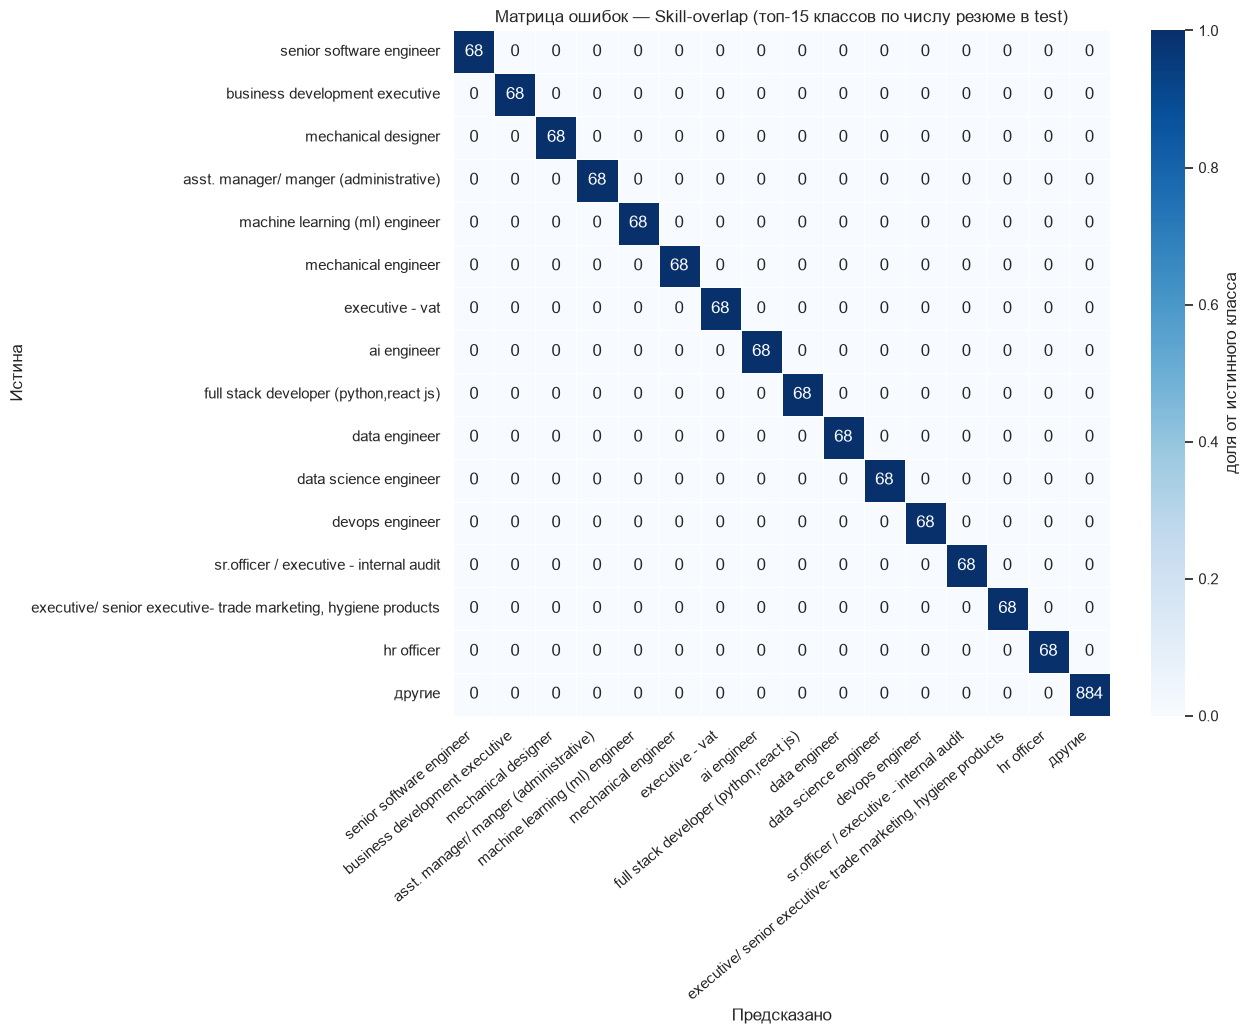

In [33]:
from sklearn.metrics import confusion_matrix, classification_report

cls_models = {n: r for n, r in results.items() if r["pred"] is not None and not n.startswith("Baseline")}
best_name = max(cls_models, key=lambda n: cls_models[n]["macro_f1"])
R = results[best_name]
y_pred, dec, classes_ = R["pred"], R["dec"], list(R["classes"])
correct = (y_te == y_pred)
print(f"Модель для разбора: «{best_name}»  | Accuracy {correct.mean():.3f}, Macro-F1 {R['macro_f1']:.3f}, подобранный C = {R['best_C']}")

support = Counter(y_te)
labels_all = [c for c in CLASSES if support[c] > 0]
show = [c for c, _ in support.most_common(15)]
has_other = len(show) < len(labels_all)
col = lambda y: np.array([v if v in show else "другие" for v in y])
cm_labels = show + (["другие"] if has_other else [])
cm = confusion_matrix(col(y_te), col(y_pred), labels=cm_labels)
cm_norm = np.divide(cm, cm.sum(1, keepdims=True), out=np.zeros(cm.shape, dtype=float), where=cm.sum(1, keepdims=True) > 0)

fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, xticklabels=cm_labels, yticklabels=cm_labels,
            cbar_kws={"label": "доля от истинного класса"}, linewidths=0.4, ax=ax)
ax.set_xlabel("Предсказано"); ax.set_ylabel("Истина"); ax.set_title(f"Матрица ошибок — {best_name.split(' (')[0]} (топ-{len(show)} классов по числу резюме в test)")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

In [34]:
rep_cls = classification_report(y_te, y_pred, labels=labels_all, output_dict=True, zero_division=0)
per_class = pd.DataFrame(rep_cls).T.loc[labels_all]
per_class["train"] = [int((y_tr == c).sum()) for c in labels_all]
per_class = per_class.rename(columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1", "support": "test"})
print("Хуже всего:"); display(per_class.sort_values("F1").head(8).round(3))
print("Лучше всего:"); display(per_class.sort_values("F1", ascending=False).head(5).round(3))
if len(per_class) > 3 and per_class["train"].nunique() > 1:
    rho = spearmanr(per_class["train"], per_class["F1"])
    print(f"Связь размера класса в train и F1: Spearman ρ = {rho.statistic:.2f} (p = {rho.pvalue:.3f})")

Хуже всего:


,Precision,Recall,F1,test,train
project coordinator (civil),1.0,1.0,1.0,68.0,137
hr officer,1.0,1.0,1.0,68.0,137
civil engineer,1.0,1.0,1.0,68.0,137
site engineer,1.0,1.0,1.0,68.0,137
senior software engineer,1.0,1.0,1.0,68.0,136
"executive/ senior executive- trade marketing, hygiene products",1.0,1.0,1.0,68.0,136
business development executive,1.0,1.0,1.0,68.0,136
ai engineer,1.0,1.0,1.0,68.0,136


Лучше всего:


,Precision,Recall,F1,test,train
project coordinator (civil),1.0,1.0,1.0,68.0,137
hr officer,1.0,1.0,1.0,68.0,137
civil engineer,1.0,1.0,1.0,68.0,137
site engineer,1.0,1.0,1.0,68.0,137
senior software engineer,1.0,1.0,1.0,68.0,136


Связь размера класса в train и F1: Spearman ρ = nan (p = nan)


In [35]:
# самые частые путаницы + возможная причина: насколько похожи центроиды TF-IDF этих классов
pairs = Counter((t, p) for t, p in zip(y_te, y_pred) if t != p)
conf = pd.DataFrame([{"истина": t, "предсказано": p, "ошибок": c, "доля от класса": c / support[t]} for (t, p), c in pairs.most_common(10)])
display(conf.round(3))

tf_res = results[next(n for n in results if "TF-IDF" in n)]
Xtr_tf, feat = tf_res["Xtr"], _tf.v.get_feature_names_out()
cent = {c: np.asarray(Xtr_tf[y_tr == c].mean(0)).ravel() for c in CLASSES if (y_tr == c).any()}
cn = {c: v / (np.linalg.norm(v) or 1) for c, v in cent.items()}
names_c = list(cn); M = np.vstack([cn[c] for c in names_c]); simM = M @ M.T
med_sim = float(np.median(simM[np.triu_indices(len(names_c), 1)]))
print(f"Медианная косинусная близость центроидов TF-IDF между ВСЕМИ парами классов: {med_sim:.3f}")
rows = []
for (t, p), c in pairs.most_common(6):
    if t in cn and p in cn:
        s_tp = float(cn[t] @ cn[p])
        top_t = set(feat[np.argsort(-cent[t])[:30]]); top_p = set(feat[np.argsort(-cent[p])[:30]])
        rows.append({"истина → предсказано": f"{t} → {p}", "близость центроидов": s_tp, "выше медианы": s_tp > med_sim,
                     "общие топ-термы": ", ".join(sorted(top_t & top_p)[:6])})
cause = pd.DataFrame(rows); display(cause.round(3))

""


Медианная косинусная близость центроидов TF-IDF между ВСЕМИ парами классов: 0.092


""


In [36]:
# ошибки vs длина резюме, число найденных навыков, уверенность модели
te_skill_counts = np.array([len(s) for s in predict_skills(nlp_eval, te_texts)])
def acc_by_quartile(values, name):
    q = pd.qcut(pd.Series(values).rank(method="first"), 4, labels=["Q1 (мин.)", "Q2", "Q3", "Q4 (макс.)"])
    g = pd.DataFrame({"q": q, "ok": correct}).groupby("q", observed=True).agg(accuracy=("ok", "mean"), n=("ok", "size"))
    g["диапазон"] = [f"{pd.Series(values)[q == k].min():.0f}–{pd.Series(values)[q == k].max():.0f}" for k in g.index]
    g.index.name = name; return g
by_len, by_sk = acc_by_quartile(te["n_words"].to_numpy(), "длина резюме (слов)"), acc_by_quartile(te_skill_counts, "найдено навыков")
display(by_len.round(3)); display(by_sk.round(3))

if dec is not None:
    srt = np.sort(dec, axis=1); margin = srt[:, -1] - srt[:, -2]
    cidx = {c: i for i, c in enumerate(classes_)}
    true_score = np.array([dec[i, cidx[t]] if t in cidx else np.nan for i, t in enumerate(y_te)])
    rank_true = np.where(np.isnan(true_score), np.nan, (dec > true_score[:, None]).sum(1) + 1)
    top3 = np.nanmean(rank_true[~np.isnan(rank_true)] <= 3); top5 = np.nanmean(rank_true[~np.isnan(rank_true)] <= 5)
    conf_hi = margin >= np.median(margin)
    print(f"Уверенность: средний зазор top1–top2 у верных {margin[correct].mean():.3f} vs у ошибочных {margin[~correct].mean():.3f}; "
          f"Accuracy на более уверенной половине {correct[conf_hi].mean():.3f}, на менее уверенной {correct[~conf_hi].mean():.3f}")
    print(f"Top-3 accuracy: {top3:.3f}, Top-5 accuracy: {top5:.3f} (Top-1: {correct.mean():.3f}) — насколько часто верный класс «почти угадан»")

,accuracy,n,диапазон
длина резюме (слов),,,
Q1 (мин.),1.0,476,15–51
Q2,1.0,476,51–71
Q3,1.0,476,71–95
Q4 (макс.),1.0,476,95–410


,accuracy,n,диапазон
найдено навыков,,,
Q1 (мин.),1.0,476,7–21
Q2,1.0,476,21–27
Q3,1.0,476,27–40
Q4 (макс.),1.0,476,41–161


Уверенность: средний зазор top1–top2 у верных 2.137 vs у ошибочных nan; Accuracy на более уверенной половине 1.000, на менее уверенной 1.000
Top-3 accuracy: 1.000, Top-5 accuracy: 1.000 (Top-1: 1.000) — насколько часто верный класс «почти угадан»


In [37]:
print("ПРИМЕРЫ ОШИБОК (случайные, seed фиксирован):")
wrong = np.where(~correct)[0]
pick = np.random.default_rng(SEED).choice(wrong, size=min(6, len(wrong)), replace=False) if len(wrong) else []
te_skills_sets = predict_skills(nlp_eval, te_texts)
for i in pick:
    extra = f" | ранг верного класса: {int(rank_true[i])}" if dec is not None and not np.isnan(rank_true[i]) else ""
    print(f"— истина: «{y_te[i]}» → предсказано: «{y_pred[i]}»{extra}")
    print(f"  навыки (NER): {sorted(te_skills_sets[i])[:8]}")
    print(f"  текст: {te_texts[i][:220]}…\n")

# автоматическая интерпретация
print("ИНТЕРПРЕТАЦИЯ ОШИБОК:")
worst = per_class.sort_values("F1").index[:3].tolist()
print(f"• Слабее всего распознаются классы: {worst}; их средний размер в train — {per_class.loc[worst, 'train'].mean():.0f} против {per_class['train'].mean():.0f} в среднем.")
if len(cause):
    print(f"• {cause['выше медианы'].mean():.0%} из топ-{len(cause)} путаниц приходятся на пары классов с близостью центроидов выше медианной ({med_sim:.2f}): "
          "модель путает должности с похожей лексикой, а не ошибается случайно.")
print(f"• Точность по квартилям длины резюме: " + ", ".join(f"{k}: {v:.2f}" for k, v in by_len['accuracy'].items()) + " — "
      + ("короткие резюме распознаются хуже." if by_len['accuracy'].iloc[0] < by_len['accuracy'].iloc[-1] - 0.03 else "явной зависимости от длины нет."))
print(f"• Точность по квартилям числа найденных навыков: " + ", ".join(f"{k}: {v:.2f}" for k, v in by_sk['accuracy'].items()) + ".")
print("• Что делать дальше: объединять близкие должности/иерархию классов, добавить признаки из `positions`/`major_field_of_studies`, "
      "дообучить эмбеддинги (Sentence-BERT) на резюме, смотреть Top-k вместо Top-1 в интерфейсе рекрутера.")

ПРИМЕРЫ ОШИБОК (случайные, seed фиксирован):
ИНТЕРПРЕТАЦИЯ ОШИБОК:
• Слабее всего распознаются классы: ['project coordinator (civil)', 'hr officer', 'civil engineer']; их средний размер в train — 137 против 136 в среднем.
• Точность по квартилям длины резюме: Q1 (мин.): 1.00, Q2: 1.00, Q3: 1.00, Q4 (макс.): 1.00 — явной зависимости от длины нет.
• Точность по квартилям числа найденных навыков: Q1 (мин.): 1.00, Q2: 1.00, Q3: 1.00, Q4 (макс.): 1.00.
• Что делать дальше: объединять близкие должности/иерархию классов, добавить признаки из `positions`/`major_field_of_studies`, дообучить эмбеддинги (Sentence-BERT) на резюме, смотреть Top-k вместо Top-1 в интерфейсе рекрутера.


## 12. Продуктовая модель NER и демонстрация
Продуктовая модель — `en_core_web_md` (без встроенного NER) + EntityRuler **с тем же словарём, для которого посчитаны метрики** (`vocab`-часть + кураторский список). Токенизатор у `spacy.blank("en")` и `en_core_web_md` один и тот же, поэтому результаты оценочной (blank) и продуктовой (md) моделей совпадают — это проверяется в конце.

In [38]:
from spacy import displacy

nlp, n_prod = build_ner(pattern_skills, base="md")
print(f"Продуктовый пайплайн готов. Паттернов: {n_prod}, из них мультитокенных: "
      f"{sum(1 for p in nlp.get_pipe('entity_ruler').patterns if len(p['pattern']) > 1)}")

def extract_skills(text, model=None):
    doc = (model or nlp)(clean_text(text))
    return doc, sorted({normalize_skill(ent.text) for ent in doc.ents if ent.label_ == "SKILL"})

test_text = ("I am a Senior Developer with expertise in Python, React, and PostgreSQL. "
             "I also have experience with AWS, Docker, machine learning, and deep learning. "
             "Familiar with CI/CD pipelines and Kubernetes.")
doc, extracted = extract_skills(test_text)
print("Найденные навыки:", extracted, f"(всего {len(extracted)})")
displacy.render(doc, style="ent", jupyter=True)

Продуктовый пайплайн готов. Паттернов: 3970, из них мультитокенных: 2763
Найденные навыки: ['aws', 'ci/cd', 'deep learning', 'developer', 'docker', 'kubernetes', 'machine learning', 'pipelines', 'postgresql', 'python', 'react'] (всего 11)


## 13. Prompt Engineering: генерация рекомендаций
Раньше вызов `get_groq_recommendations` был закомментирован, а `analyze_resume` его вызывал — на чистом запуске падал `NameError`. Теперь:
* если задан `GROQ_API_KEY` (переменная окружения или Kaggle Secret) и установлен пакет `groq` — рекомендации даёт LLM;
* иначе автоматически используется детерминированный rule-based вариант (тот же формат из 5 разделов), ноутбук выполняется целиком без ключей и интернета.

In [39]:
LEARNING_TIPS = {
    "kubernetes": "пройдите курс CKA и практикуйтесь на killer.sh", "mlflow": "изучите MLflow по официальной документации",
    "spark": "Databricks Academy — бесплатный курс по Spark", "airflow": "поднимите Airflow локально и напишите первые DAG",
    "terraform": "HashiCorp Learn — бесплатный курс Terraform", "golang": "tour.golang.org", "docker": "Play with Docker — бесплатная песочница",
    "aws": "AWS Free Tier + курс AWS Cloud Practitioner", "pytorch": "официальные туториалы на pytorch.org",
    "tensorflow": "TensorFlow Developer Certificate", "typescript": "документация typescriptlang.org", "postgresql": "postgresqltutorial.com",
}

def build_prompt(resume_text: str, job_description: str, analysis: dict) -> str:
    matched = ', '.join(analysis['matched']) if analysis['matched'] else 'нет совпадений'
    missing = ', '.join(analysis['missing']) if analysis['missing'] else 'все навыки присутствуют'
    return f"""You are an expert career coach and technical recruiter specializing in IT.
Analyze the following resume against a job description and provide actionable recommendations.

## Resume:
{resume_text.strip()}

## Job Description:
{job_description.strip()}

## Pre-computed Analysis:
- Skill match score: {analysis['score']:.0%}
- Matched skills: {matched}
- Missing required skills: {missing}

## Task:
Provide a structured response with:
1. **Overall Assessment** (2-3 sentences on the candidate's fit)
2. **Top 3 Strengths** (skills/experience that align well)
3. **Top 3 Gaps** (most critical missing skills or experience)
4. **Action Plan** (specific steps to improve match rate, e.g., courses, projects)
5. **Resume Optimization Tips** (2-3 concrete changes to the resume text)

Be specific, concise, and actionable. Focus on IT/tech context."""

def get_groq_recommendations(prompt: str, model: str = "llama-3.3-70b-versatile") -> str:
    key = os.environ.get("GROQ_API_KEY")
    if not key:
        try:
            from kaggle_secrets import UserSecretsClient
            key = UserSecretsClient().get_secret("GROQ_API_KEY")
        except Exception:
            pass
    if not key:
        raise RuntimeError("GROQ_API_KEY не задан")
    from groq import Groq
    resp = Groq(api_key=key).chat.completions.create(messages=[{"role": "user", "content": prompt}], model=model)
    return resp.choices[0].message.content

def rule_based_recommendations(overlap: dict, final: float) -> str:
    level = "отличное" if final >= 0.65 else "хорошее" if final >= 0.40 else "низкое"
    matched, missing = overlap["matched"], overlap["missing"]
    lines = ["## Overall Assessment",
             f"Итоговое соответствие — {level} ({final:.0%}); совпало {len(matched)} из {len(matched) + len(missing)} требуемых навыков.",
             "## Top 3 Strengths"] + [f"- {s}" for s in matched[:3]] + (["- (совпадений навыков нет)"] if not matched else [])
    lines += ["## Top 3 Gaps"] + [f"- {s}" for s in missing[:3]] + (["- (пробелов нет)"] if not missing else [])
    lines += ["## Action Plan"] + [f"- {s}: {LEARNING_TIPS.get(s, 'изучите по официальной документации и сделайте небольшой проект')}" for s in missing[:5]]
    lines += ["## Resume Optimization Tips",
              "- Добавьте измеримые результаты (например, «ускорил обработку на 40%»).",
              "- Вынесите раздел Technical Skills с явным списком технологий.",
              "- Используйте формулировки навыков из текста вакансии."]
    return "\n".join(lines)

def get_recommendations(prompt, overlap, final, use_llm="auto"):
    if use_llm in ("auto", True):
        try:
            return get_groq_recommendations(prompt), "groq"
        except Exception as exc:
            if use_llm is True:
                raise
            print(f"[LLM недоступен: {type(exc).__name__}: {str(exc)[:70]}] → используются rule-based рекомендации")
    return rule_based_recommendations(overlap, final), "rule-based"

## 14. Финальный пайплайн

In [40]:
def analyze_resume(resume_text: str, job_description: str, verbose: bool = True, use_llm="auto") -> dict:
    """1) очистка → 2) NER навыков резюме и вакансии → 3) skill overlap → 4) TF-IDF cosine (векторизатор из train) → 5) рекомендации."""
    resume_clean, job_clean = clean_text(resume_text), clean_text(job_description)
    _, resume_skills = extract_skills(resume_clean)
    _, job_skills = extract_skills(job_clean)
    overlap = skill_overlap_score(resume_skills, job_skills)
    tfidf = matcher.match(resume_clean, job_clean)
    final = round(0.6 * overlap['score'] + 0.4 * tfidf, 4)
    prompt = build_prompt(resume_text, job_description, overlap)
    recs, source = get_recommendations(prompt, overlap, final, use_llm)
    result = {"resume_skills": resume_skills, "job_skills": job_skills, "skill_overlap": overlap, "tfidf_similarity": tfidf,
              "final_score": final, "llm_prompt": prompt, "recommendations": recs, "recommendations_source": source}
    if verbose:
        print("=" * 60); print("         АНАЛИЗ СООТВЕТСТВИЯ РЕЗЮМЕ И ВАКАНСИИ"); print("=" * 60)
        print(f" Навыки кандидата   : {len(resume_skills)}: {', '.join(resume_skills[:10])}…")
        print(f" Требования вакансии: {len(job_skills)}: {', '.join(job_skills[:10])}…")
        print(f" Skill Overlap      : {overlap['score']:.1%}\n TF-IDF Similarity  : {tfidf:.4f}\n Итоговая оценка    : {final:.1%}")
        print(f" Совпали  : {', '.join(overlap['matched']) or 'нет'}\n Отсутствуют: {', '.join(overlap['missing']) or 'нет'}")
        print("=" * 60); print(f"Рекомендации (источник: {source}):\n{recs}")
    return result

SAMPLE_RESUME = """
Experienced Data Scientist with 4 years of industry experience.
Proficient in Python, pandas, scikit-learn, TensorFlow, and PyTorch.
Strong background in machine learning, deep learning, and NLP.
Worked with PostgreSQL, MongoDB, AWS S3, and Spark.
Familiar with Docker, Git, and CI/CD pipelines.
Experience building REST APIs with FastAPI and Flask.
"""
SAMPLE_JOB = """
We are looking for a Machine Learning Engineer to join our team.
Requirements:
- Python (3+ years)
- TensorFlow or PyTorch
- Experience with NLP and transformer models
- SQL databases (PostgreSQL preferred)
- Docker and Kubernetes
- AWS or GCP cloud platforms
- MLflow or similar experiment tracking
- Strong understanding of statistics and algorithms
"""
result = analyze_resume(SAMPLE_RESUME, SAMPLE_JOB)

[LLM недоступен: RuntimeError: GROQ_API_KEY не задан] → используются rule-based рекомендации
         АНАЛИЗ СООТВЕТСТВИЯ РЕЗЮМЕ И ВАКАНСИИ
 Навыки кандидата   : 20: aws, ci/cd, data scientist, deep learning, docker, fastapi, flask, git, machine learning, mongodb…
 Требования вакансии: 16: algorithms, aws, cloud, databases, docker, gcp, kubernetes, machine learning engineer, mlflow, natural language processing…
 Skill Overlap      : 43.8%
 TF-IDF Similarity  : 0.2468
 Итоговая оценка    : 36.1%
 Совпали  : aws, docker, natural language processing, postgresql, python, pytorch, tensorflow
 Отсутствуют: algorithms, cloud, databases, gcp, kubernetes, machine learning engineer, mlflow, sql, statistics
Рекомендации (источник: rule-based):
## Overall Assessment
Итоговое соответствие — низкое (36%); совпало 7 из 16 требуемых навыков.
## Top 3 Strengths
- aws
- docker
- natural language processing
## Top 3 Gaps
- algorithms
- cloud
- databases
## Action Plan
- algorithms: изучите по официальной

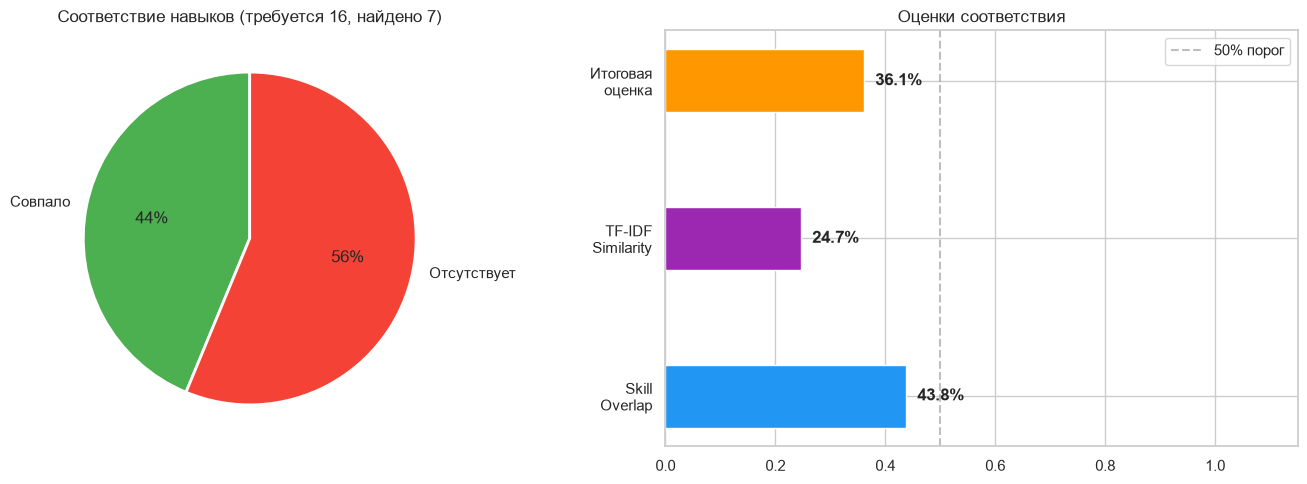

In [41]:
ov = result["skill_overlap"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(ov["matched"]) + len(ov["missing"]) > 0:
    axes[0].pie([len(ov["matched"]), len(ov["missing"])], labels=['Совпало', 'Отсутствует'], colors=['#4CAF50', '#F44336'],
                autopct='%1.0f%%', startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
    axes[0].set_title(f"Соответствие навыков (требуется {len(result['job_skills'])}, найдено {len(ov['matched'])})")
vals = [ov['score'], result['tfidf_similarity'], result['final_score']]
bars = axes[1].barh(['Skill\nOverlap', 'TF-IDF\nSimilarity', 'Итоговая\nоценка'], vals, color=['#2196F3', '#9C27B0', '#FF9800'], height=0.4)
axes[1].set_xlim(0, 1.15); axes[1].axvline(0.5, color='gray', linestyle='--', alpha=0.5, label='50% порог')
for b, v in zip(bars, vals):
    axes[1].text(v + 0.02, b.get_y() + b.get_height() / 2, f'{v:.1%}', va='center', fontweight='bold')
axes[1].set_title('Оценки соответствия'); axes[1].legend()
plt.tight_layout(); plt.show()

## 15. Сохранение моделей и проверка
Сохраняются **те же** объекты, для которых посчитаны метрики: словарь из части `vocab` и TF-IDF, обученный на части `train`. Затем модели загружаются с диска и метрики пересчитываются — они должны совпасть. Из `tfidf.pkl` убран служебный атрибут `stop_words_` (список всех отброшенных термов; не нужен для `transform`, но сильно раздувал файл).

In [42]:
import copy
model_dir, tfidf_path, meta_path = OUT_DIR / "nlp_model", OUT_DIR / "tfidf.pkl", OUT_DIR / "model_metadata.json"
if model_dir.exists():
    shutil.rmtree(model_dir)
nlp.to_disk(model_dir)

vec_to_save = copy.deepcopy(matcher.vectorizer)
if hasattr(vec_to_save, "stop_words_"):
    vec_to_save.stop_words_ = None
with open(tfidf_path, "wb") as f:
    pickle.dump(vec_to_save, f)

tf_row, best_row = results[next(n for n in results if "TF-IDF" in n)], results[best_name]
metadata = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"), "seed": SEED, "dataset_md5": DATA_MD5,
    "versions": {"python": platform.python_version(), "spacy": spacy.__version__, "spacy_model": nlp_lem.meta.get("version"),
                 "sklearn": __import__("sklearn").__version__, "numpy": np.__version__},
    "split": {"fractions": SPLIT_FRACTIONS, "sizes": df["split"].value_counts().to_dict(), "duplicates_removed": int(n1 - len(df))},
    "ner": {"n_patterns": n_prod, "vocab_split_skills": len(VOCAB_SKILLS), "curated_skills": len(CURATED),
            "test_metrics": {k: res_main[k] for k in ("n_docs", "P_micro", "R_micro", "F1_micro", "P_macro", "R_macro", "F1_macro")},
            "leaky_protocol_F1_micro": variants["1. Утечка: словарь из ВСЕХ строк, оценка на test"][0]["F1_micro"]},
    "tfidf": {"params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in TFIDF_PARAMS.items()},
              "fit_docs": len(train_texts_all), "n_terms": len(vec_to_save.vocabulary_)},
    "matching_test": {"n_classes": K, "n_test": len(te),
                      "tfidf": {k: tf_row[k] for k in ("accuracy", "macro_f1", "P@5", "P@10", "MRR")},
                      "best_representation": best_name, "best": {k: best_row[k] for k in ("accuracy", "macro_f1", "P@5", "P@10", "MRR")}},
}
meta_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
sz = lambda p: sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 2**20 if Path(p).is_dir() else Path(p).stat().st_size / 2**20
print(f"Сохранено: {model_dir}/ ({sz(model_dir):.1f} MB), {tfidf_path} ({sz(tfidf_path):.2f} MB), {meta_path}")

Сохранено: nlp_model/ (54.9 MB), tfidf.pkl (0.42 MB), model_metadata.json


In [43]:
# проверка «загрузили с диска → метрики совпали»
nlp_back = spacy.load(model_dir)
with open(tfidf_path, "rb") as f:
    vec_back = pickle.load(f)

preds_back = predict_skills(nlp_back, ner_input(test_rows))
res_back = eval_ner(preds_back, gold_test)
assert preds_back == preds_test, "предсказания сохранённой NER-модели отличаются от оценённой"
assert abs(res_back["F1_micro"] - res_main["F1_micro"]) < 1e-12
print(f"✓ NER: сохранённая модель даёт те же предсказания; F1(micro) = {res_back['F1_micro']:.4f}")

_pairs = list(zip(te_texts[:50], te["job_text"].tolist()[:50]))
def _sims(vec):
    return [float(cosine_similarity(vec.transform([clean_text(a)]), vec.transform([clean_text(b)]))[0][0]) for a, b in _pairs]
assert np.allclose(_sims(vec_back), _sims(matcher.vectorizer))
print("✓ TF-IDF: перезагруженный векторизатор даёт те же косинусные сходства")

# согласованность с nlp_pipeline.py (если лежит рядом с сохранёнными моделями)
_pp = OUT_DIR / "nlp_pipeline.py"
if _pp.exists():
    try:
        spec = importlib.util.spec_from_file_location("nlp_pipeline", _pp)
        npl = importlib.util.module_from_spec(spec); spec.loader.exec_module(npl)
        ref = npl.analyze_texts(SAMPLE_RESUME, SAMPLE_JOB)
        print(f"✓ nlp_pipeline.py загрузил артефакты ({npl.MODEL_INFO['ner_model']}); итоговый балл на примере: "
              f"пайплайн {ref['final_score']} vs ноутбук {result['final_score']}")
        assert abs(ref["final_score"] - result["final_score"]) < 1e-3, "nlp_pipeline.py и ноутбук расходятся"
    except Exception as exc:
        print("⚠ проверка nlp_pipeline.py не выполнена:", repr(exc)[:200])
else:
    print(f"(nlp_pipeline.py не найден в {OUT_DIR} — проверка согласованности пропущена)")

✓ NER: сохранённая модель даёт те же предсказания; F1(micro) = 0.9995
✓ TF-IDF: перезагруженный векторизатор даёт те же косинусные сходства
✓ nlp_pipeline.py загрузил артефакты (nlp_model/ (сохранённая модель из ноутбука), +0 навыков вакансий); итоговый балл на примере: пайплайн 0.3615 vs ноутбук 0.3615


## Выводы

In [44]:
m = metadata
print("РЕЗУЛЬТАТЫ ЭТОГО ЗАПУСКА (все числа — на отложенной части test, не участвовавшей в построении словаря и обучении):\n")
print(f"1. NER (словарь из {m['ner']['vocab_split_skills']} навыков vocab-части + {m['ner']['curated_skills']} кураторских = {m['ner']['n_patterns']} паттернов): "
      f"P={m['ner']['test_metrics']['P_micro']:.3f}, R={m['ner']['test_metrics']['R_micro']:.3f}, F1={m['ner']['test_metrics']['F1_micro']:.3f} (micro); "
      f"F1 macro по документам {m['ner']['test_metrics']['F1_macro']:.3f}. С утечкой словаря F1 был бы {m['ner']['leaky_protocol_F1_micro']:.3f}.")
print(f"2. Matching ({K} классов, {len(te)} резюме): TF-IDF Accuracy {tf_row['accuracy']:.3f}, Macro-F1 {tf_row['macro_f1']:.3f}, MRR {tf_row['MRR']:.3f}; "
      f"лучшее представление — «{best_name}» (Macro-F1 {best_row['macro_f1']:.3f}).")
print("\nОГРАНИЧЕНИЯ")
print("• Эталон NER — списки навыков, которые кандидаты сами указали в полях skills / related_skils_in_job, а не размеченные спаны в свободном тексте; "
      "поэтому оценивается покрытие словаря неизвестными навыками (OOV), а не качество разбора прозы. Для последнего нужна ручная разметка.")
print("• Эталон matching — название вакансии из датасета; пары «резюме — вакансия» могли быть составлены автоматически, поэтому потолок качества неизвестен.")
print("• Одно разбиение train/test: доверительные интервалы bootstrap учитывают только выборку теста, но не выбор разбиения; для финального отчёта — повторить с несколькими SEED / кросс-валидацией.")
print("• spaCy-эмбеддинги — статические усреднённые векторы; Sentence-BERT усекает длинные тексты до ~256 токенов.")
print("• Словарь из 40% данных беднее, чем из 100%: для продукта можно после оценки пересобрать словарь на всех данных, но тогда метрики нужно считать на новом отложенном наборе.")

РЕЗУЛЬТАТЫ ЭТОГО ЗАПУСКА (все числа — на отложенной части test, не участвовавшей в построении словаря и обучении):

1. NER (словарь из 3911 навыков vocab-части + 138 кураторских = 3970 паттернов): P=1.000, R=0.999, F1=1.000 (micro); F1 macro по документам 1.000. С утечкой словаря F1 был бы 1.000.
2. Matching (28 классов, 1904 резюме): TF-IDF Accuracy 1.000, Macro-F1 1.000, MRR 1.000; лучшее представление — «Skill-overlap (NER → бинарные навыки)» (Macro-F1 1.000).

ОГРАНИЧЕНИЯ
• Эталон NER — списки навыков, которые кандидаты сами указали в полях skills / related_skils_in_job, а не размеченные спаны в свободном тексте; поэтому оценивается покрытие словаря неизвестными навыками (OOV), а не качество разбора прозы. Для последнего нужна ручная разметка.
• Эталон matching — название вакансии из датасета; пары «резюме — вакансия» могли быть составлены автоматически, поэтому потолок качества неизвестен.
• Одно разбиение train/test: доверительные интервалы bootstrap учитывают только выборку тест